# Project A INAIL 1 end to end pilot V4
This notebook prepares movement sequences and MVC-normalized lifting outcomes, then compares compact CNN, GRU and Transformer models against mean and Ridge references. Run all cells. Performance is generated from local data; no precomputed research results are supplied.

Required packages: numpy, pandas, scipy, matplotlib, scikit-learn, torch. Install a CUDA-compatible PyTorch build in the environment for GPU use. This notebook does not install or replace packages. CPU is supported. It displays detected hardware and uses all operational visible CUDA GPUs through DataParallel. Small workloads can have multi-GPU overhead. FP32 is used for V100 and newer-GPU portability.

Default: full participant-held-out evaluation, three fixed seeds, primary LI1/LI2 cohort and secondary S01–S10 three-condition cohort. This is a comparative pilot with fixed compact architectures, not an untouched confirmatory study. SMOKE_TEST runs two outer folds, one seed and three epochs and labels results incomplete. Local source files remain unchanged. Code cells have no comments.

Outputs: exclusion and target ledgers, prepared arrays, source hashes, checkpoints, split membership, training histories, predictions, worker-balanced metrics, per-muscle and per-condition results, paired worker-bootstrap intervals, figures and a compact feedback ZIP. ZIP excludes raw signals, prepared sequence arrays and checkpoints by default; those remain in the run directory.

Scientific contract: retrospective whole-lift prediction; task information and movement are inputs; EMG and a worker's MVC references are used only to construct reference outcomes. Nominal TDF timing supports alignment but does not certify hardware latency. Endpoint: lifting-phase filtered EMG RMS divided by the larger of two valid filtered 250 ms RMS p95 reference contractions, multiplied by 100. These are operational reference-normalized outcomes, not injury probabilities or certified maximal activation percentages.

In [1]:
from pathlib import Path
from datetime import datetime, timezone
from collections import defaultdict
import copy
import hashlib
import io
import json
import os
import platform
import random
import re
import shutil
import struct
import sys
import time
import traceback
import zipfile
import numpy as np
import pandas as pd
from scipy.io import loadmat
from scipy.signal import butter, sosfiltfilt
from scipy.stats import spearmanr
import matplotlib.pyplot as plt
from sklearn.linear_model import Ridge
from sklearn.model_selection import GroupKFold
from sklearn.preprocessing import StandardScaler
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader
from IPython.display import display

PROJECT_ROOT=Path("/home/rafsan/Documents/GitHub/IPEXBIO/Project_A")
DATA_ROOT=Path.home()/"Downloads/INAIL_1/Dataset1/DATA"
NOTEBOOK_FILENAME="ProjectA_INAIL1_EndToEnd_V4.ipynb"
SMOKE_TEST=False
RUN_SECONDARY=True
SEEDS=[11,22,33]
MAX_EPOCHS=100
PATIENCE=15
BATCH_SIZE=32
LEARNING_RATE=0.001
WEIGHT_DECAY=0.001
SEQUENCE_LENGTH=128
WIDTH=32
DROPOUT=0.2
BOOTSTRAP_REPEATS=2000
USE_ALL_CUDA_GPUS=True
REUSE_COMPLETED_RUN=None
TARGET_CHANNELS=["RESL","RESI","LESL","LESI"]
BODY_MARKERS=["c7","Sacrum","RShould","LShould","RElbow","LElbow","RRadio","LRadio","RAsis","LAsis","RKnee1","LKnee1"]
MAX_FIGURES=12
PROJECT_ROOT=PROJECT_ROOT.expanduser().resolve()
DATA_ROOT=DATA_ROOT.expanduser().resolve()
if not DATA_ROOT.is_dir():
    raise FileNotFoundError(f"Set DATA_ROOT to the existing raw DATA directory: {DATA_ROOT}")
PROJECT_ROOT.mkdir(parents=True,exist_ok=True)
if REUSE_COMPLETED_RUN is None:
    RUN_DIR=PROJECT_ROOT/"results"/"INAIL1_EndToEnd_V4"/datetime.now(timezone.utc).strftime("run_%Y%m%dT%H%M%S_%fZ")
else:
    RUN_DIR=Path(REUSE_COMPLETED_RUN).expanduser().resolve()
    if not RUN_DIR.is_relative_to(PROJECT_ROOT):
        raise ValueError("Resume directory must be under PROJECT_ROOT")
RUN_DIR.mkdir(parents=True,exist_ok=True)
for folder in ["figures","jobs","checkpoints"]:
    (RUN_DIR/folder).mkdir(exist_ok=True)
if SMOKE_TEST:
    SEEDS=SEEDS[:1]
    MAX_EPOCHS=3
    PATIENCE=2
    BOOTSTRAP_REPEATS=100
    RUN_SECONDARY=False

gpu_inventory=[]
operational_gpus=[]
if torch.cuda.is_available():
    for i in range(torch.cuda.device_count()):
        try:
            props=torch.cuda.get_device_properties(i)
            with torch.cuda.device(i):
                probe=torch.randn(8,8,device=f"cuda:{i}")
                float((probe@probe).sum().item())
                torch.cuda.synchronize(i)
            operational_gpus.append(i)
            gpu_inventory.append({"id":i,"name":props.name,"VRAM_GB":round(props.total_memory/2**30,2),"capability":str(torch.cuda.get_device_capability(i)),"operational":True})
        except Exception as exc:
            gpu_inventory.append({"id":i,"operational":False,"error":str(exc)})
GPU_IDS=operational_gpus if USE_ALL_CUDA_GPUS else operational_gpus[:1]
DEVICE=torch.device(f"cuda:{GPU_IDS[0]}" if GPU_IDS else "cpu")
if GPU_IDS:
    torch.cuda.set_device(GPU_IDS[0])
    torch.backends.cuda.matmul.allow_tf32=False
    torch.backends.cudnn.allow_tf32=False
    if hasattr(torch.backends.cuda,"enable_flash_sdp"):
        torch.backends.cuda.enable_flash_sdp(False)
        torch.backends.cuda.enable_mem_efficient_sdp(False)
        torch.backends.cuda.enable_math_sdp(True)
torch.set_num_threads(min(8,os.cpu_count() or 1))
hardware={"host":platform.node(),"OS":platform.platform(),"CPU":platform.processor(),"CPU_logical_cores":os.cpu_count(),"python":sys.version,"torch":torch.__version__,"torch_CUDA_build":torch.version.cuda,"visible_CUDA_count":torch.cuda.device_count(),"GPUs":gpu_inventory,"selected_GPU_ids":GPU_IDS,"execution":f"DataParallel on {len(GPU_IDS)} GPUs" if len(GPU_IDS)>1 else str(DEVICE),"precision":"float32","smoke_test":SMOKE_TEST}
print(json.dumps(hardware,indent=2))
print("PROJECT ROOT:",PROJECT_ROOT)
print("DATA ROOT:",DATA_ROOT)
print("RUN DIRECTORY:",RUN_DIR)
print("MODE:","SMOKE TEST: incomplete evaluation" if SMOKE_TEST else "FULL PILOT")
pd.set_option("display.max_columns",30)
pd.set_option("display.max_rows",30)

{
  "host": "user-GPU",
  "OS": "Linux-6.8.0-138-generic-x86_64-with-glibc2.35",
  "CPU": "x86_64",
  "CPU_logical_cores": 20,
  "python": "3.11.14 (main, Oct 21 2025, 18:31:21) [GCC 11.2.0]",
  "torch": "2.5.1+cu121",
  "torch_CUDA_build": "12.1",
  "visible_CUDA_count": 2,
  "GPUs": [
    {
      "id": 0,
      "name": "Tesla V100-PCIE-32GB",
      "VRAM_GB": 31.73,
      "capability": "(7, 0)",
      "operational": true
    },
    {
      "id": 1,
      "name": "Tesla V100-PCIE-32GB",
      "VRAM_GB": 31.73,
      "capability": "(7, 0)",
      "operational": true
    }
  ],
  "selected_GPU_ids": [
    0,
    1
  ],
  "execution": "DataParallel on 2 GPUs",
  "precision": "float32",
  "smoke_test": false
}
PROJECT ROOT: /home/rafsan/Documents/GitHub/IPEXBIO/Project_A
DATA ROOT: /home/rafsan/Downloads/INAIL_1/Dataset1/DATA
RUN DIRECTORY: /home/rafsan/Documents/GitHub/IPEXBIO/Project_A/results/INAIL1_EndToEnd_V4/run_20261113T105528_260101Z
MODE: FULL PILOT


## Fixed preparation rules and source reader
Movement phase reconstruction uses a 4 Hz low-pass crate-height signal, its velocity crossing 0.025 m/s and a height maximum near the supplied movement stop. Supplied events constrain the search; EMG never determines phase boundaries. The filter order and 50 ms onset persistence below are fixed engineering choices, not claims to reproduce the authors' exact implementation. Original-marker support is checked within the phase. MATLAB processed marker coordinates are used as movement inputs; gaps in original TDF markers are logged. No response-driven alignment is performed.

In [2]:
class Reader:
    def __init__(self,data):
        self.data=memoryview(data)
        self.pos=0
    def take(self,n):
        if n<0 or self.pos+n>len(self.data):
            raise ValueError(f"Read outside block at {self.pos}, length {n}, block bytes {len(self.data)}")
        out=self.data[self.pos:self.pos+n]
        self.pos+=n
        return out
    def unpack(self,fmt):
        return struct.unpack(fmt,self.take(struct.calcsize(fmt)))
    def integer(self):
        return self.unpack("<i")[0]
    def string(self,n):
        return bytes(self.take(n)).split(b"\x00")[0].decode("cp1252",errors="replace")
    def count(self,max_value=10000000):
        v=self.integer()
        if not 0<=v<=max_value:
            raise ValueError(f"Invalid count {v}")
        return v
    def finish(self):
        if self.pos!=len(self.data):
            raise ValueError(f"Unconsumed block bytes: {len(self.data)-self.pos}")

def parse_tracks(r,count,n_samples,dimensions):
    if count*n_samples*dimensions>100000000:
        raise ValueError("Requested allocation exceeds audit limit")
    tracks=[]
    for j in range(count):
        label=r.string(256)
        nseg=r.count(10000)
        r.take(4)
        segments=[r.unpack("<ii") for _ in range(nseg)]
        a=np.full((n_samples,dimensions),np.nan,dtype=np.float32)
        end=0
        for start,length in segments:
            if start<0 or length<0 or start+length>n_samples or start<end:
                raise ValueError(f"Invalid or overlapping segment {start,length}")
            a[start:start+length]=np.frombuffer(r.take(length*dimensions*4),dtype="<f4").reshape(length,dimensions)
            end=start+length
        tracks.append({"label":label,"segments":segments,"data":a[:,0] if dimensions==1 else a})
    return tracks

def parse_tdf(path):
    payload=path.read_bytes()
    if payload[:16]!=bytes.fromhex("824b6041d31184ca6000b6ac16680c08"):
        raise ValueError("Unrecognized TDF signature")
    if len(payload)<64:
        raise ValueError("Truncated TDF header")
    version,n=struct.unpack_from("<Ii",payload,16)
    if version!=1 or not 0<n<=1000 or 64+n*288>len(payload):
        raise ValueError("Unsupported TDF version or directory")
    entries=[]
    blocks={}
    ranges=[]
    for j in range(n):
        kind,fmt,offset,size=struct.unpack_from("<IIii",payload,64+j*288)
        if not size:
            continue
        if offset<64+n*288 or size<0 or offset+size>len(payload):
            raise ValueError("Invalid block boundary")
        ranges.append((offset,offset+size))
        entries.append({"type":kind,"format":fmt,"offset":offset,"bytes":size})
        if kind not in [5,11,16]:
            continue
        if kind in blocks:
            raise ValueError("Multiple blocks of a required type")
        r=Reader(payload[offset:offset+size])
        if kind==5:
            if fmt not in [1,2]:
                raise ValueError(f"Unsupported marker format {fmt}")
            frames=r.count()
            frequency=r.integer()
            start=r.unpack("<f")[0]
            tracks=r.count(1000)
            volume=np.frombuffer(r.take(12),dtype="<f4").tolist()
            rotation=np.frombuffer(r.take(36),dtype="<f4").reshape(3,3).tolist()
            translation=np.frombuffer(r.take(12),dtype="<f4").tolist()
            flag=r.unpack("<I")[0]
            if fmt==1:
                links=r.count(100000)
                r.take(4+links*8)
            block={"frequency":frequency,"start":start,"count":frames,"flag":flag,"volume":volume,"rotation":rotation,"translation":translation,"tracks":parse_tracks(r,tracks,frames,3)}
        elif kind==11:
            if fmt!=1:
                raise ValueError(f"Unsupported EMG format {fmt}")
            signals=r.count(1000)
            frequency=r.integer()
            start=r.unpack("<f")[0]
            samples=r.count()
            channel_map=np.frombuffer(r.take(signals*2),dtype="<i2").tolist()
            block={"frequency":frequency,"start":start,"count":samples,"channel_map":channel_map,"tracks":parse_tracks(r,signals,samples,1)}
        else:
            if fmt!=1:
                raise ValueError(f"Unsupported event format {fmt}")
            events=r.count(10000)
            start=r.unpack("<f")[0]
            values=[]
            for _ in range(events):
                label=r.string(256)
                event_type=r.unpack("<I")[0]
                length=r.count(100000)
                array=np.frombuffer(r.take(length*4),dtype="<f4").astype(float)
                values.append({"label":label,"type":event_type,"values":array.tolist()})
            block={"start":start,"events":values}
        r.finish()
        if kind in [5,11] and (block["frequency"]<=0 or not np.isfinite(block["start"])):
            raise ValueError("Invalid stream clock header")
        blocks[kind]=block
    ranges.sort()
    if any(a[1]>b[0] for a,b in zip(ranges,ranges[1:])):
        raise ValueError("Overlapping block ranges")
    return {"version":version,"entries":entries,"blocks":blocks,"sha256":hashlib.sha256(payload).hexdigest()}

In [3]:
def entries(value):
    if isinstance(value, dict):
        return [value]
    if isinstance(value, (list, tuple)):
        return list(value)
    if isinstance(value, np.ndarray):
        return list(value.reshape(-1))
    return []

def numeric(value):
    a = np.asarray(value)
    return a if a.dtype.kind in "biufc" else None

def leaves(value, prefix=""):
    if isinstance(value, dict):
        for key, item in value.items():
            yield from leaves(item, f"{prefix}.{key}" if prefix else key)
    else:
        a = numeric(value)
        if a is not None:
            yield prefix, a

def digest(value):
    h = hashlib.sha256()
    count = 0
    for name, a in sorted(leaves(value)):
        h.update(name.encode())
        h.update(str(a.shape).encode())
        h.update(a.dtype.str.encode())
        h.update(np.ascontiguousarray(a).tobytes())
        count += a.size
    return h.hexdigest() if count else None

def scalar(value):
    try:
        a = np.asarray(value)
        return float(a.reshape(-1)[0]) if a.size == 1 else np.nan
    except Exception:
        return np.nan

def rate(value):
    r = scalar(value)
    return r if np.isfinite(r) and r > 0 else np.nan

def longest_run(mask):
    padded = np.r_[False, np.asarray(mask, dtype=bool).reshape(-1), False]
    edges = np.flatnonzero(padded[1:] != padded[:-1])
    return int(np.max(edges[1::2] - edges[::2])) if edges.size else 0

def quality(a, fs):
    a = np.asarray(a)
    values = np.real(a).astype(float)
    flat = values.reshape(-1)
    good = flat[np.isfinite(flat)]
    row_bad = ~np.isfinite(values) if values.ndim <= 1 else ~np.isfinite(values).reshape(values.shape[0], -1).all(axis=1)
    result = {"shape": str(tuple(a.shape)), "dtype": str(a.dtype), "samples": int(a.shape[0]) if a.ndim else 1, "elements": int(a.size), "nonfinite_fraction": float(1 - len(good) / a.size) if a.size else np.nan, "longest_missing_samples": longest_run(row_bad), "fs": fs}
    result["duration_s"] = result["samples"] / fs if np.isfinite(fs) and a.size else np.nan
    if good.size:
        result.update(minimum=float(np.min(good)), maximum=float(np.max(good)), mean=float(np.mean(good)), std=float(np.std(good)), rms=float(np.sqrt(np.mean(good ** 2))), abs_p95=float(np.percentile(np.abs(good), 95)), extreme_value_fraction=float(np.mean((good == good.min()) | (good == good.max()))))
        if values.ndim == 1 and len(values) > 1:
            valid = np.isfinite(values[:-1]) & np.isfinite(values[1:])
            result["equal_adjacent_fraction"] = float(np.mean(np.diff(values)[valid] == 0)) if valid.any() else np.nan
    return result

def moving_rms_reference(a, fs):
    a = np.asarray(a, dtype=float).reshape(-1)
    if not np.isfinite(fs) or len(a) < 2 or not np.isfinite(a).all():
        return np.nan
    a = a - np.mean(a)
    width = max(1, min(len(a), int(round(0.25 * fs))))
    rms = np.sqrt(np.maximum(0, np.convolve(a ** 2, np.ones(width) / width, mode="valid")))
    return float(np.percentile(rms, 95))

def describe_schema(value, path="root", depth=0):
    if depth > 6:
        return []
    if isinstance(value, dict):
        rows = [{"path": path, "kind": "dict", "detail": list(value)}]
        for key, item in value.items():
            rows.extend(describe_schema(item, f"{path}.{key}", depth+1))
        return rows
    if isinstance(value, (list, tuple)):
        return [{"path": path, "kind": "list", "detail": len(value)}] + (describe_schema(value[0], path + "[0]", depth+1) if value else [])
    if isinstance(value, np.ndarray):
        return [{"path": path, "kind": "array", "detail": {"shape": list(value.shape), "dtype": str(value.dtype)}}]
    return [{"path": path, "kind": type(value).__name__, "detail": str(value)[:200]}]

GROUPS = {"Kinematic_data": ("data_3D", "fs_3D"), "sEMG": ("data_sEMG", "fs_sEMG"), "Ground_forces_and_moments": ("platform_data", "fs_forces"), "MVC": ("MVC_data", "fs_MVC")}

In [4]:
def sid_from(text):
    m=re.search(r"S0*(\d+)",Path(str(text)).name,re.I)
    return f"S{int(m.group(1)):02d}" if m else None

def task_key(text):
    return str(text).lower().removesuffix(".tdf")

def recording_identity(text):
    name=Path(str(text)).name
    sid=sid_from(name)
    li=re.search(r"LI(\d+)",name,re.I)
    rep=re.search(r"LI\d+[A-Za-z]*[_ -](\d+)(?:\.[^.]+)?$",name,re.I)
    return sid,int(li.group(1)) if li else None,int(rep.group(1)) if rep else None

def sha_file(p):
    h=hashlib.sha256()
    with p.open("rb") as stream:
        for chunk in iter(lambda:stream.read(1048576),b""):
            h.update(chunk)
    return h.hexdigest()

def clean(x):
    if isinstance(x,dict):
        return {str(k):clean(v) for k,v in x.items()}
    if isinstance(x,(list,tuple)):
        return [clean(v) for v in x]
    if isinstance(x,np.ndarray):
        return clean(x.tolist())
    if isinstance(x,np.generic):
        return clean(x.item())
    if isinstance(x,float) and not np.isfinite(x):
        return None
    if isinstance(x,Path):
        return str(x)
    return x

def save_json(path,value):
    path=Path(path)
    path.write_text(json.dumps(clean(value),indent=2,allow_nan=False),encoding="utf-8")

def constant_intervals(a,min_length=1):
    a=np.asarray(a).reshape(-1)
    if not len(a):
        return []
    edges=np.r_[0,np.flatnonzero((a[1:]!=a[:-1])|~np.isfinite(a[1:])|~np.isfinite(a[:-1]))+1,len(a)]
    return [(int(s),int(e)) for s,e in zip(edges[:-1],edges[1:]) if e-s>=min_length and np.isfinite(a[s])]

def emg_filter(a,fs):
    a=np.asarray(a,dtype=float).reshape(-1)
    if len(a)<64 or not np.isfinite(a).all() or fs<=50:
        raise ValueError("Invalid EMG filter input")
    return sosfiltfilt(butter(4,[20,min(450,fs*0.45)],btype="bandpass",fs=fs,output="sos"),a-a.mean())

def reference_value(a,fs):
    a=np.asarray(a,dtype=float).reshape(-1)
    if len(a)<int(fs) or not np.isfinite(a).all():
        raise ValueError("MVC recording absent, short or nonfinite")
    valid=np.ones(len(a),dtype=bool)
    for s,e in constant_intervals(a,max(2,int(.05*fs))):
        valid[s:e]=False
    edges=np.flatnonzero(np.diff(np.r_[False,valid,False].astype(int)))
    values=[]
    seconds=0
    for lo,hi in zip(edges[::2],edges[1::2]):
        if hi-lo>=int(.5*fs):
            f=emg_filter(a[lo:hi],fs)
            width=int(.25*fs)
            values.extend(np.sqrt(np.maximum(0,np.convolve(f*f,np.ones(width)/width,"valid"))).tolist())
            seconds+=(hi-lo)/fs
    if seconds<1 or not values:
        raise ValueError("Insufficient nonconstant MVC recording")
    result=float(np.percentile(values,95))
    if not np.isfinite(result) or result<=0:
        raise ValueError("Nonpositive MVC reference")
    return result,seconds

def reconstruct_phase(k):
    fs=rate(k.get("fs_3D"))
    d=k.get("data_3D",{})
    arrays=[np.asarray(d.get(name,[]),dtype=float) for name in ["load_RL1","load_RL2","load_LL1","load_LL2"]]
    if not np.isfinite(fs) or any(a.ndim!=2 or a.shape[1]!=3 or not np.isfinite(a).all() for a in arrays) or len({len(a) for a in arrays})!=1:
        raise ValueError("Invalid processed crate markers")
    crate=np.median(np.stack(arrays),axis=0)
    y=sosfiltfilt(butter(4,4,fs=fs,output="sos"),crate[:,1])
    v=np.gradient(y,1/fs)
    stop0=scalar(k.get("events",{}).get("stop"))-1
    start0=scalar(k.get("events",{}).get("start"))-1
    if not np.isfinite([start0,stop0]).all() or not 0<=start0<stop0<len(y):
        raise ValueError("Invalid supplied movement anchors")
    lo=max(0,int(start0-.5*fs))
    hi=min(len(y),int(stop0+.5*fs)+1)
    stop=lo+int(np.argmax(y[lo:hi]))
    persistent=max(2,int(.05*fs))
    crossings=[j for j in range(max(lo,1),stop-persistent) if v[j-1]<=.025 and np.all(v[j:j+persistent]>.025)]
    if not crossings:
        raise ValueError("No persistent positive lifting threshold crossing")
    start=min(crossings,key=lambda j:abs(j-start0))
    duration=(stop-start)/fs
    excursion=y[stop]-y[start]
    if not .3<=duration<=4 or not .10<=excursion<=1.0:
        raise ValueError("Implausible phase duration or crate excursion in assumed metre coordinates")
    return start,stop,crate,{"motion_fs":fs,"duration_s":duration,"crate_excursion_m":float(excursion),"onset_difference_from_MAT_s":(start-start0)/fs,"stop_difference_from_MAT_s":(stop-stop0)/fs,"start_index":start,"stop_index":stop}

def movement_sequence(k,start,stop,crate,tdf_motion):
    d=k["data_3D"]
    data=[]
    for name in BODY_MARKERS:
        a=np.asarray(d.get(name,[]),dtype=float)
        if a.shape!=(len(crate),3) or not np.isfinite(a[start:stop]).all():
            raise ValueError("Processed body marker absent or nonfinite: "+name)
        data.append(a[start:stop])
    pelvis=(np.asarray(d["RAsis"])[start:stop]+np.asarray(d["LAsis"])[start:stop])/2
    relative=np.concatenate([a-pelvis for a in data]+[crate[start:stop]-pelvis,pelvis-pelvis[0]],axis=1)
    if not np.isfinite(relative).all() or np.max(np.abs(relative))>5:
        raise ValueError("Movement coordinate scale or finiteness failed")
    t=np.linspace(0,1,len(relative))
    out=np.stack([np.interp(np.linspace(0,1,SEQUENCE_LENGTH),t,relative[:,j]) for j in range(relative.shape[1])],axis=1)
    supports=[]
    comparisons=[]
    tdf_lookup={tr["label"]:tr["data"] for tr in tdf_motion["tracks"]}
    for name,label in [("load_RL1","RL1"),("load_RL2","RL2"),("load_LL1","LL1"),("load_LL2","LL2")]:
        b=tdf_lookup.get(label)
        a=np.asarray(d[name])
        if b is None or b.shape!=a.shape:
            raise ValueError("Crate source shape mismatch")
        valid=np.isfinite(b[start:stop]).all(axis=1)
        supports.append(valid)
        if valid.any():
            comparisons.append(float(np.sqrt(np.mean((a[start:stop][valid]-b[start:stop][valid])**2))))
    support=np.sum(np.stack(supports),axis=0)>=2
    unsupported=longest_run(~support)/k["fs_3D"]
    if support.mean()<.95 or unsupported>.05 or not comparisons or max(comparisons)>.005:
        raise ValueError("Insufficient original crate support or processed/source mismatch within phase")
    return out.astype(np.float32),float(support.mean()),float(unsupported)

## Prepare the modelling table once
Primary targets are RESL, RESI, LESL and LESI. A trial enters the common four-output cohort only if all four targets and movement inputs pass the fixed operational rules. Both records in cross-participant duplicate families are quarantined. Within-participant exact recording duplicates retain one deterministic representative. Source matching uses participant/condition/repetition; a missing repetition suffix requires signal and crate correspondence. Unrelated channel failures do not automatically reject these four targets. Targets above 100 are flagged and retained; no outcome clipping or response-based exclusions are applied. MVC ratio above 2 holds the affected channel rather than automatically accepting its larger contraction.

Preparing 1/17 S01


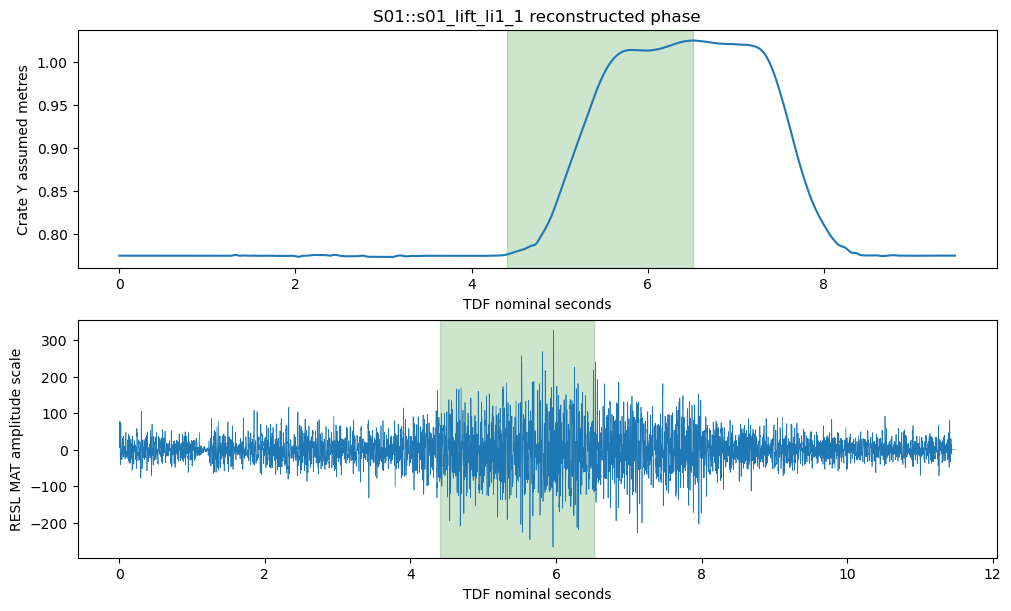

Preparing 2/17 S10


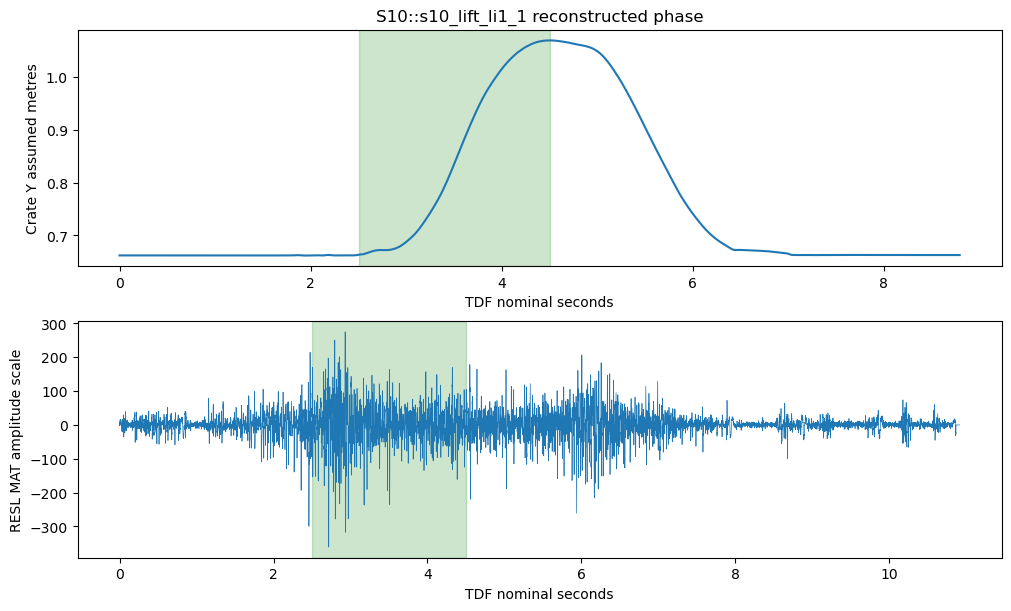

Preparing 3/17 S11


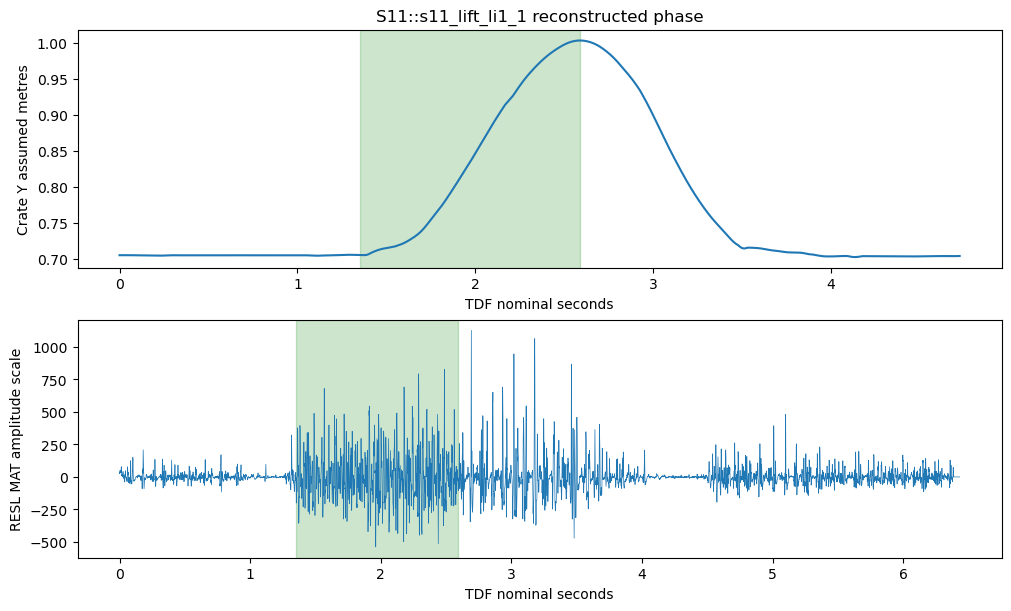

Preparing 4/17 S12


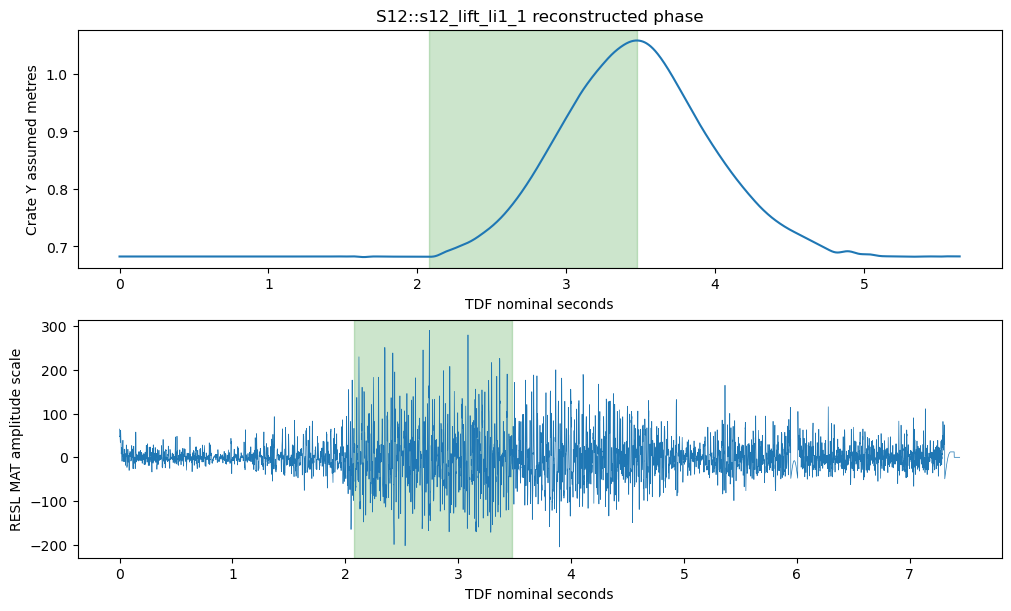

Preparing 5/17 S13


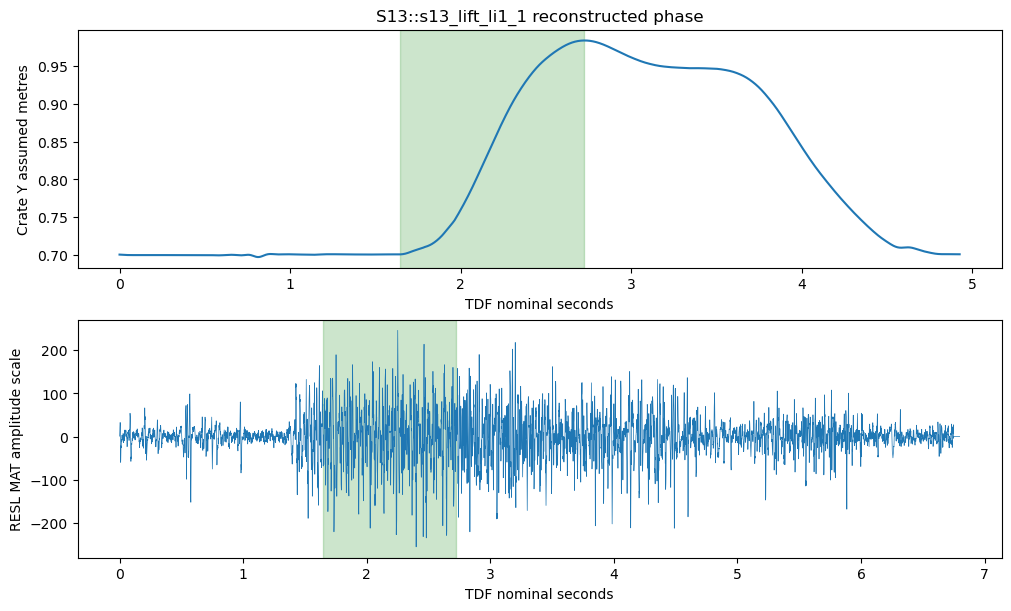

Preparing 6/17 S14


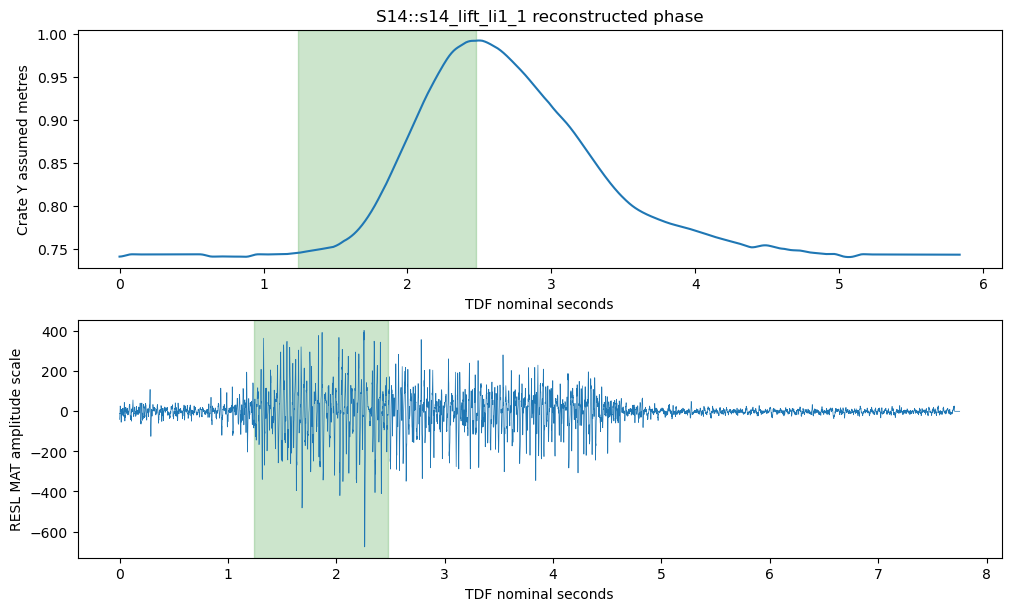

Preparing 7/17 S15


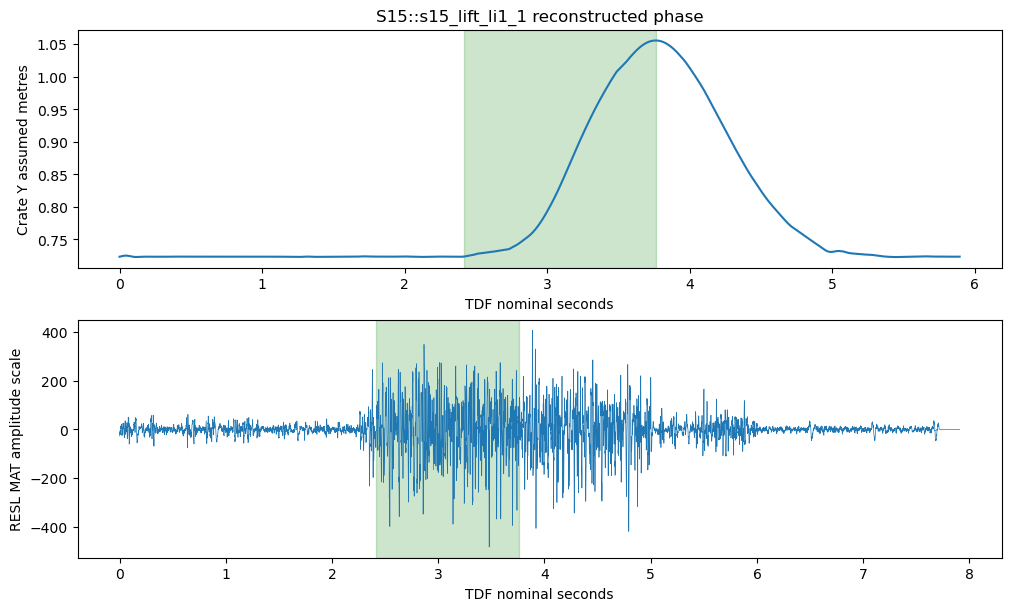

Preparing 8/17 S16


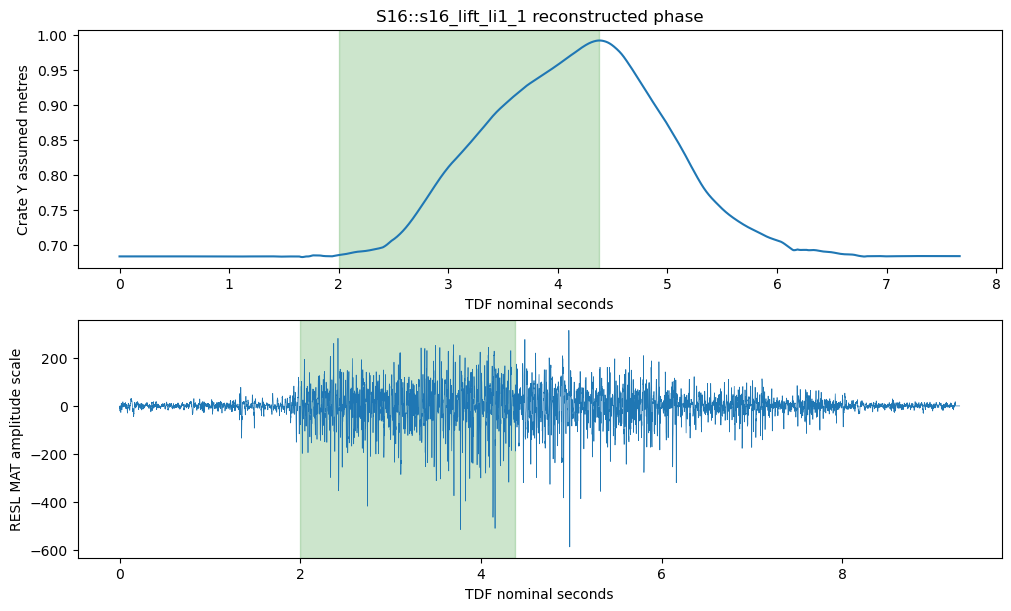

Preparing 9/17 S17


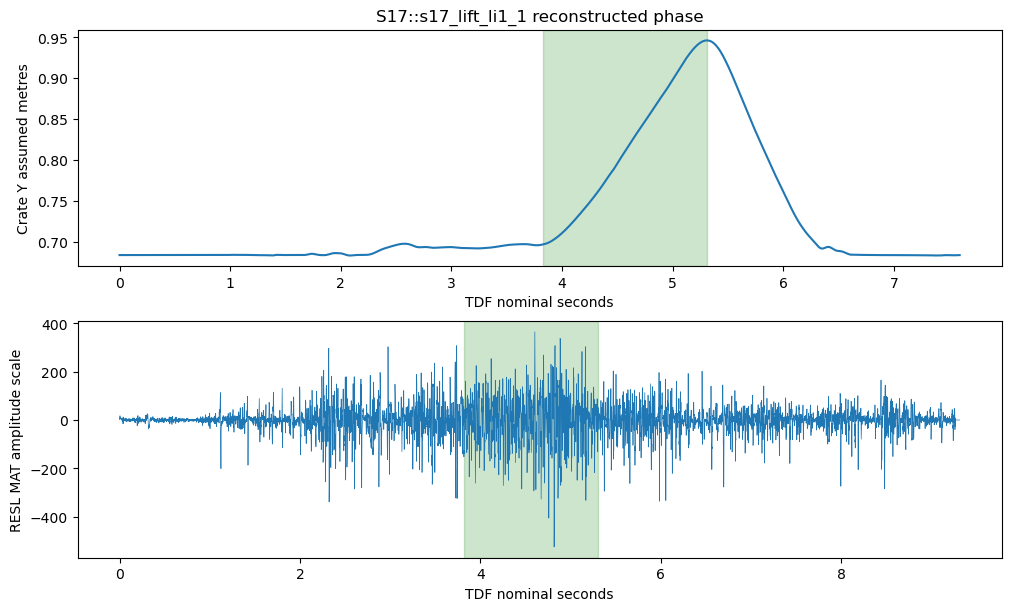

Preparing 10/17 S02


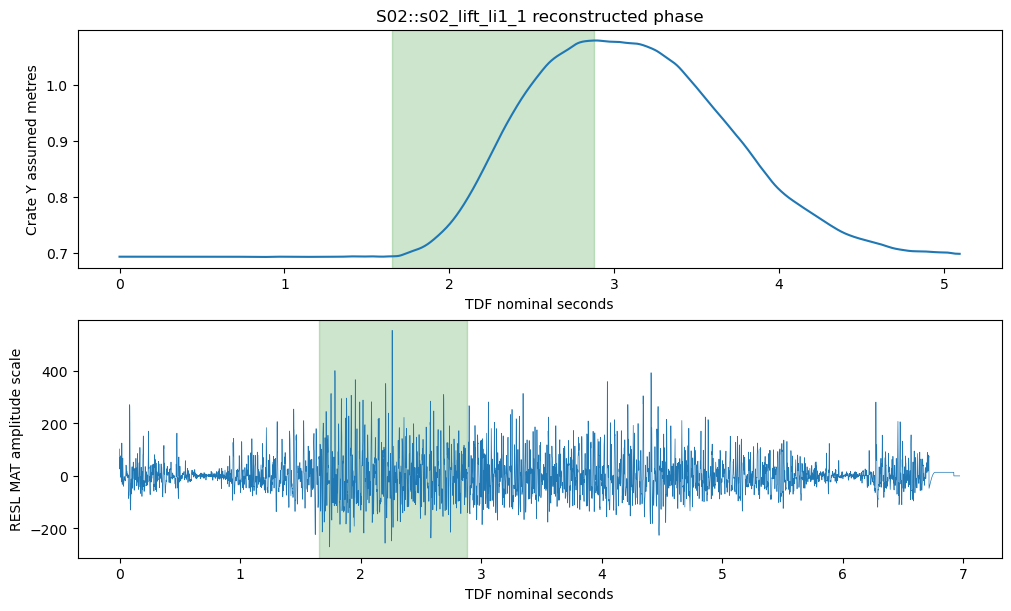

Preparing 11/17 S03


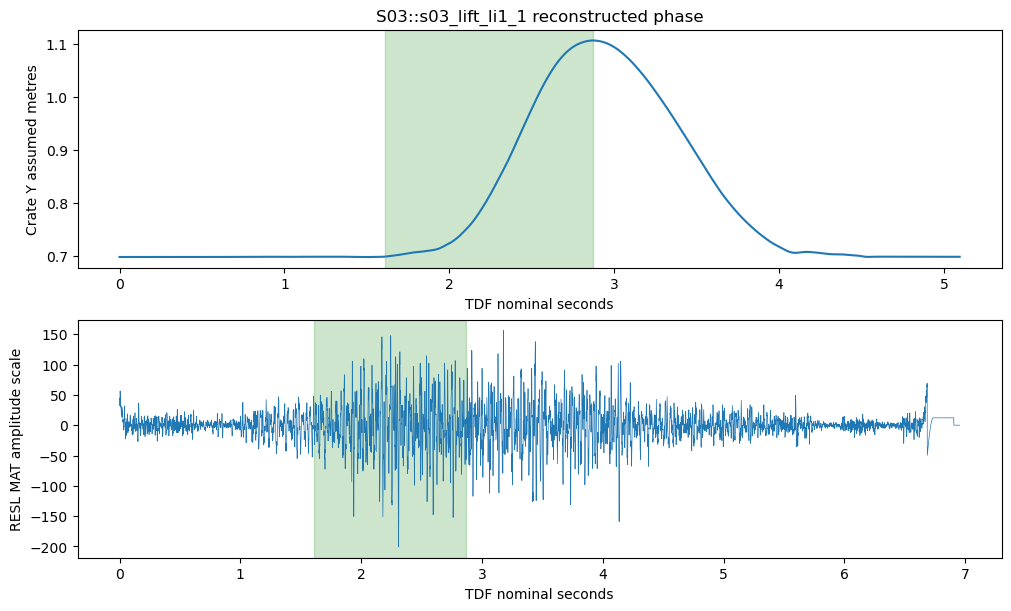

Preparing 12/17 S04


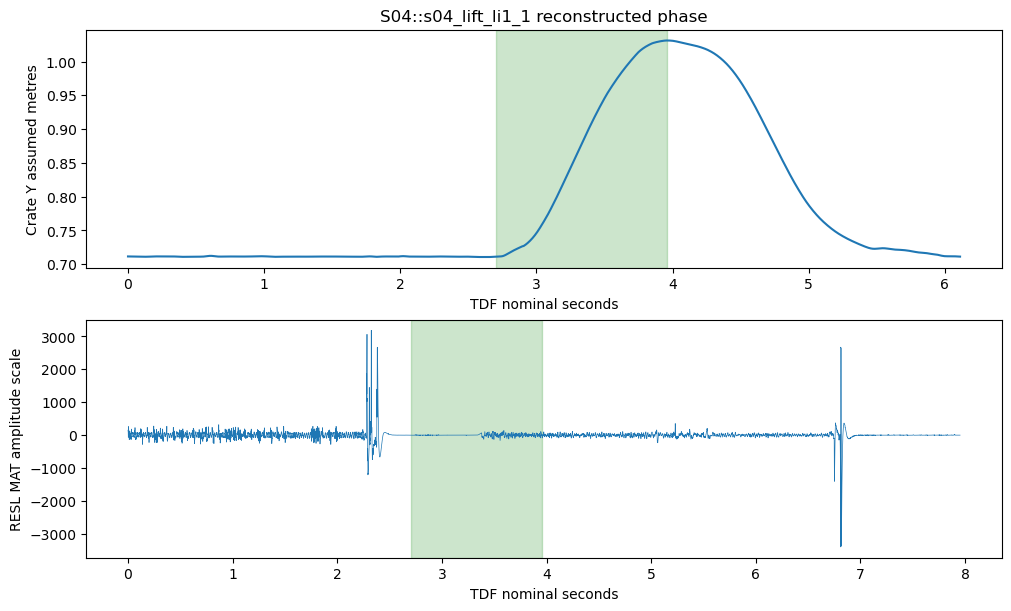

Preparing 13/17 S05
Preparing 14/17 S06
Preparing 15/17 S07
Preparing 16/17 S08
Preparing 17/17 S09


sum  count
subject LI            
S01     1     2      3
        2     3      3
        3     3      3
S02     1     3      3
        2     3      3
...         ...    ...
S15     2     3      3
S16     1     3      3
        2     2      3
S17     1     3      3
        2     3      3

[44 rows x 2 columns]

,trials
reason,
within_subject_duplicate_nonrepresentative,6
cross_subject_duplicate_quarantine,2
Invalid EMG phase: LESI,1


Prepared sequences: (123, 128, 42) targets: (123, 4) workers: 17
Target values exceeding 100: 14 retained without clipping


In [5]:
mat_paths=sorted(p for p in DATA_ROOT.rglob("*_all_trials.mat") if "__MACOSX" not in p.parts and not p.name.startswith("._"))
tdf_paths=sorted(p for p in DATA_ROOT.rglob("*") if p.is_file() and p.suffix.lower()==".tdf" and "__MACOSX" not in p.parts and not p.name.startswith("._"))
if not mat_paths or not tdf_paths:
    raise FileNotFoundError("Both MAT and original TDF files are needed")
tdf_index=defaultdict(list)
fallback_index=defaultdict(list)
for p in tdf_paths:
    identity=recording_identity(p.name)
    if identity[2] is None:
        fallback_index[identity[:2]].append(p)
    else:
        tdf_index[identity].append(p)
records=[]
references=[]
source_files=[]
preparation_errors=[]
phase_plots=0
for index,path in enumerate(mat_paths,1):
    sid=sid_from(path.name)
    print(f"Preparing {index}/{len(mat_paths)} {sid}",flush=True)
    try:
        raw=loadmat(path,simplify_cells=True)
        roots=[v for k,v in raw.items() if not k.startswith("__") and isinstance(v,dict) and "Kinematic_data" in v]
        if len(roots)!=1:
            raise ValueError("Ambiguous MATLAB root")
        data=roots[0]
        source_files.append({"path":str(path.relative_to(DATA_ROOT)),"sha256":sha_file(path)})
        mvc_ref={}
        for ch in TARGET_CHANNELS:
            values=[]
            for j,m in enumerate(entries(data.get("MVC")),1):
                try:
                    val,seconds=reference_value(m.get("MVC_data",{}).get(ch,[]),rate(m.get("fs_MVC")))
                    values.append(val)
                    references.append({"subject":sid,"channel":ch,"entry":j,"reference":val,"nonconstant_seconds":seconds,"status":"passed"})
                except Exception as exc:
                    references.append({"subject":sid,"channel":ch,"entry":j,"status":"failed","reason":str(exc)})
            if len(values)==2 and min(values)>0 and max(values)/min(values)<=2:
                mvc_ref[ch]=max(values)
        emap=defaultdict(list)
        for e in entries(data.get("sEMG")):
            emap[task_key(e.get("task",""))].append(e)
        for k in entries(data.get("Kinematic_data")):
            task=task_key(k.get("task",""))
            tid=sid+"::"+task
            es=emap.get(task,[])
            record={"subject":sid,"trial_id":tid,"task":task,"LI":recording_identity(task)[1],"motion_hash":digest(k.get("data_3D",{})),"emg_hash":digest(es[0].get("data_sEMG",{})) if len(es)==1 else None,"status":"failed","reason":"","sequence":None,"target":None}
            records.append(record)
            try:
                if len(es)!=1:
                    raise ValueError("Missing or ambiguous EMG task")
                e=es[0]
                identity=recording_identity(task)
                candidates=tdf_index.get(identity,[]) or fallback_index.get(identity[:2],[])
                if len(candidates)!=1:
                    raise ValueError("Missing or ambiguous TDF source")
                p=candidates[0]
                parsed=parse_tdf(p)
                motion=parsed["blocks"].get(5)
                emg=parsed["blocks"].get(11)
                if motion is None or emg is None:
                    raise ValueError("Required TDF blocks absent")
                source_files.append({"path":str(p.relative_to(DATA_ROOT)),"sha256":parsed["sha256"]})
                fm,fe=rate(k.get("fs_3D")),rate(e.get("fs_sEMG"))
                if motion["frequency"]!=fm or emg["frequency"]!=fe:
                    raise ValueError("Sampling rate mismatch")
                if motion["count"]!=len(np.asarray(k["data_3D"]["load_RL1"])):
                    raise ValueError("Movement frame count mismatch")
                start,stop,crate,phase=reconstruct_phase(k)
                sequence,support,gap=movement_sequence(k,start,stop,crate,motion)
                t0=motion["start"]+start/fm
                t1=motion["start"]+stop/fm
                i0=int(np.ceil((t0-emg["start"])*fe-1e-5))
                i1=int(np.ceil((t1-emg["start"])*fe-1e-5))
                if not 0<=i0<i1<=emg["count"]:
                    raise ValueError("Reconstructed phase outside EMG interval")
                target=[]
                for ch in TARGET_CHANNELS:
                    if ch not in mvc_ref:
                        raise ValueError("MVC reference failed fixed rules: "+ch)
                    a=np.asarray(e.get("data_sEMG",{}).get(ch,[]),dtype=float).reshape(-1)
                    matches=[]
                    for tr in emg["tracks"]:
                        b=tr["data"]
                        if len(a)==len(b) and len(a)>0 and np.isfinite(b).all() and np.isfinite(a).all() and np.max(np.abs(a-b.astype(float)*1e6))<=1e-8:
                            matches.append(tr)
                    if len(matches)!=1:
                        raise ValueError("Target channel mapping not unique: "+ch)
                    part=a[i0:i1]
                    if not np.isfinite(part).all() or np.std(part)==0:
                        raise ValueError("Invalid EMG phase: "+ch)
                    longest=max((max(0,min(hi,i1)-max(lo,i0)) for lo,hi in constant_intervals(a)),default=0)/fe
                    if longest>=.05 or np.mean(part==0)>.01:
                        raise ValueError("Constant or padded EMG phase: "+ch)
                    lo=max(0,i0-int(.25*fe));hi=min(len(a),i1+int(.25*fe))
                    if not np.isfinite(a[lo:hi]).all():
                        lo,hi=i0,i1
                    filtered=emg_filter(a[lo:hi],fe)
                    value=100*float(np.sqrt(np.mean(filtered[i0-lo:i1-lo]**2)))/mvc_ref[ch]
                    if not np.isfinite(value):
                        raise ValueError("Nonfinite normalized outcome")
                    target.append(value)
                    record[ch+"_constant_seconds"]=longest
                record.update(status="candidate",reason="",sequence=sequence,target=np.asarray(target,dtype=np.float32),tdf_path=str(p.relative_to(DATA_ROOT)),tdf_sha256=parsed["sha256"],crate_source_supported_fraction=support,crate_source_longest_gap_s=gap,nominal_offset_s=motion["start"]-emg["start"],phase_start_TDF_s=t0,phase_stop_TDF_s=t1,emg_start_index=i0,emg_stop_exclusive=i1,**phase)
                for ch,val in zip(TARGET_CHANNELS,target):
                    record[ch+"_target"]=val
                if phase_plots<MAX_FIGURES and (task.endswith('li1_1') or sid=="S07" and task.endswith('li2_1')):
                    fig,axes=plt.subplots(2,1,figsize=(10,6),constrained_layout=True)
                    axes[0].plot(np.arange(len(crate))/fm+motion['start'],crate[:,1])
                    axes[1].plot(np.arange(len(e['data_sEMG']['RESL']))/fe+emg['start'],e['data_sEMG']['RESL'],linewidth=.5)
                    for ax in axes:
                        ax.axvspan(t0,t1,color='green',alpha=.2)
                        ax.set_xlabel('TDF nominal seconds')
                    axes[0].set_title(tid+' reconstructed phase')
                    axes[0].set_ylabel('Crate Y assumed metres')
                    axes[1].set_ylabel('RESL MAT amplitude scale')
                    fig.savefig(RUN_DIR/'figures'/f'phase_{task}.png',dpi=120)
                    plt.show();plt.close(fig)
                    phase_plots+=1
            except Exception as exc:
                record['reason']=str(exc)
    except Exception as exc:
        preparation_errors.append({'subject':sid,'error':str(exc),'traceback':traceback.format_exc()})
ledger=pd.DataFrame([{k:v for k,v in r.items() if k not in ['sequence','target']} for r in records])
if ledger.empty:
    save_json(RUN_DIR/'preparation_errors.json',preparation_errors)
    raise RuntimeError('No MATLAB trial records could be inspected')
ledger['cross_subject_quarantine']=False
ledger['duplicate_nonrepresentative']=False
for field in ['motion_hash','emg_hash']:
    for fingerprint,frame in ledger.dropna(subset=[field]).groupby(field):
        if len(frame)>1:
            if frame.subject.nunique()>1:
                ledger.loc[frame.index,'cross_subject_quarantine']=True
            else:
                ordered=frame.assign(candidate_priority=~frame.status.eq('candidate')).sort_values(['candidate_priority','trial_id'])
                ids=ordered.index
                ledger.loc[ids[1:],'duplicate_nonrepresentative']=True
ledger['included']=ledger.status.eq('candidate') & ~ledger.cross_subject_quarantine & ~ledger.duplicate_nonrepresentative
ledger.loc[ledger.cross_subject_quarantine,'reason']='cross_subject_duplicate_quarantine'
ledger.loc[ledger.duplicate_nonrepresentative & ~ledger.cross_subject_quarantine,'reason']='within_subject_duplicate_nonrepresentative'
ledger.to_csv(RUN_DIR/'trial_ledger.csv',index=False)
pd.DataFrame(references).to_csv(RUN_DIR/'MVC_reference_ledger.csv',index=False)
save_json(RUN_DIR/'preparation_errors.json',preparation_errors)
save_json(RUN_DIR/'source_manifest.json',source_files)
selected=np.flatnonzero(ledger.included.to_numpy())
if not len(selected):
    raise RuntimeError(f'No included trials. Share {RUN_DIR}/trial_ledger.csv and MVC_reference_ledger.csv; no exclusions will be bypassed automatically.')
X=np.stack([records[i]['sequence'] for i in selected]).astype(np.float32)
Y=np.stack([records[i]['target'] for i in selected]).astype(np.float32)
meta=ledger.iloc[selected].reset_index(drop=True)
C=np.eye(3,dtype=np.float32)[meta.LI.to_numpy(dtype=int)-1]
D=meta[['duration_s']].to_numpy(dtype=np.float32)
N=np.concatenate([C,D],axis=1)
S=np.concatenate([X.mean(axis=1),X.std(axis=1),X.min(axis=1),X.max(axis=1),D],axis=1)
np.savez_compressed(RUN_DIR/'prepared_dataset.npz',X=X,Y=Y,C=C,N=N,S=S,subjects=meta.subject.to_numpy(dtype=str),trial_ids=meta.trial_id.to_numpy(dtype=str))
meta.to_csv(RUN_DIR/'included_trials.csv',index=False)
display(ledger.groupby(['subject','LI']).included.agg(['sum','count']))
display(ledger.loc[~ledger.included,'reason'].value_counts().rename_axis('reason').to_frame('trials'))
print('Prepared sequences:',X.shape,'targets:',Y.shape,'workers:',meta.subject.nunique())
print('Target values exceeding 100:',int((Y>100).sum()),'retained without clipping')

## Models and participant-separated training
The three neural models receive identical normalized movement sequences plus task one-hot indicators and duration. CNN uses convolutions, GRU recurrence and Transformer positional attention. Fixed width 32 and one small encoder are used; parameter counts are reported rather than assumed equal.

References: worker-balanced training mean, task-only Ridge, task-plus-duration Ridge and task-plus-movement-summary Ridge. All prescribed task parameters are constant within a condition, so categorical condition indicators encode their task identity. No EMG, MVC, worker ID or test-worker outcome is a predictive feature. Demographic descriptors are omitted because they are incomplete for seven participants.

Outer evaluation leaves one worker out. Ridge regularization is selected using grouped inner folds. Neural epoch selection uses two held-out workers from the outer training cohort; models are then reinitialized and refitted on the complete outer training cohort for the selected number of epochs. Scaling is fitted anew on each fitting cohort. Three seeds quantify training variability; seed-ensemble predictions are reported separately. All models use the same included trials. No hyperparameter selection uses outer test performance.

In [6]:
def seed_all(seed):
    random.seed(seed);np.random.seed(seed);torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark=False
    torch.backends.cudnn.deterministic=True

def worker_weights(groups):
    groups=np.asarray(groups)
    counts=pd.Series(groups).value_counts()
    return np.asarray([len(groups)/(len(counts)*counts[g]) for g in groups],dtype=np.float32)

def worker_mae(y,p,groups):
    values=np.abs(np.asarray(y)-np.asarray(p)).mean(axis=1)
    return float(pd.DataFrame({'subject':groups,'value':values}).groupby('subject').value.mean().mean())

class SequenceModel(nn.Module):
    def __init__(self,kind,channels,context):
        super().__init__()
        self.kind=kind
        if kind=='CNN':
            self.encoder=nn.Sequential(nn.Conv1d(channels,WIDTH,5,padding=2),nn.GroupNorm(4,WIDTH),nn.GELU(),nn.Dropout(DROPOUT),nn.Conv1d(WIDTH,WIDTH,5,padding=2),nn.GroupNorm(4,WIDTH),nn.GELU(),nn.AdaptiveAvgPool1d(1))
        elif kind=='GRU':
            self.encoder=nn.GRU(channels,WIDTH,num_layers=1,batch_first=True)
        elif kind=='Transformer':
            self.project=nn.Linear(channels,WIDTH)
            position=torch.arange(SEQUENCE_LENGTH,dtype=torch.float32).unsqueeze(1)
            divisor=torch.exp(torch.arange(0,WIDTH,2,dtype=torch.float32)*(-np.log(10000.0)/WIDTH))
            pe=torch.zeros(SEQUENCE_LENGTH,WIDTH)
            pe[:,0::2]=torch.sin(position*divisor)
            pe[:,1::2]=torch.cos(position*divisor)
            self.register_buffer('position',pe.unsqueeze(0))
            layer=nn.TransformerEncoderLayer(WIDTH,4,dim_feedforward=WIDTH*2,dropout=DROPOUT,batch_first=True,activation='gelu')
            self.encoder=nn.TransformerEncoder(layer,1,enable_nested_tensor=False)
        else:
            raise ValueError(kind)
        self.head=nn.Sequential(nn.LayerNorm(WIDTH+context),nn.Linear(WIDTH+context,16),nn.GELU(),nn.Dropout(DROPOUT),nn.Linear(16,len(TARGET_CHANNELS)))
    def forward(self,x,context):
        if self.kind=='CNN':
            encoded=self.encoder(x.transpose(1,2)).squeeze(-1)
        elif self.kind=='GRU':
            self.encoder.flatten_parameters()
            _,hidden=self.encoder(x)
            encoded=hidden[-1]
        else:
            encoded=self.encoder(self.project(x)+self.position[:,:x.shape[1]]).mean(dim=1)
        return self.head(torch.cat([encoded,context],dim=1))

def scalers_for(x,n,y):
    xs=StandardScaler().fit(x.reshape(-1,x.shape[-1]))
    ns=StandardScaler().fit(n)
    ys=StandardScaler().fit(y)
    return xs,ns,ys

def transform_x(x,scaler):
    return scaler.transform(x.reshape(-1,x.shape[-1])).reshape(x.shape).astype(np.float32)

def predict_network(net,x,n,ys,batch_size=128):
    net.eval()
    out=[]
    with torch.no_grad():
        for lo in range(0,len(x),batch_size):
            a=torch.from_numpy(x[lo:lo+batch_size]).to(DEVICE)
            b=torch.from_numpy(n[lo:lo+batch_size]).to(DEVICE)
            out.append(net(a,b).detach().cpu().numpy())
    return ys.inverse_transform(np.concatenate(out)).astype(float)

def fit_network(kind,x,n,y,groups,seed,epochs,validation=None):
    seed_all(seed)
    xs,ns,ys=scalers_for(x,n,y)
    xx,nnn,yy=transform_x(x,xs),ns.transform(n).astype(np.float32),ys.transform(y).astype(np.float32)
    base=SequenceModel(kind,x.shape[-1],n.shape[-1]).to(DEVICE)
    parameter_count=sum(p.numel() for p in base.parameters() if p.requires_grad)
    net=nn.DataParallel(base,device_ids=GPU_IDS,output_device=GPU_IDS[0]) if len(GPU_IDS)>1 else base
    optimizer=torch.optim.AdamW(net.parameters(),lr=LEARNING_RATE,weight_decay=WEIGHT_DECAY)
    generator=torch.Generator().manual_seed(seed)
    dataset=TensorDataset(torch.from_numpy(xx),torch.from_numpy(nnn),torch.from_numpy(yy),torch.from_numpy(worker_weights(groups)))
    loader=DataLoader(dataset,batch_size=min(BATCH_SIZE,len(dataset)),shuffle=True,num_workers=0,pin_memory=bool(GPU_IDS),generator=generator)
    history=[]
    best=float('inf');best_epoch=epochs;stale=0
    started=time.perf_counter()
    for epoch in range(1,epochs+1):
        net.train()
        losses=[]
        for bx,bn,by,bw in loader:
            bx,bn,by,bw=[a.to(DEVICE,non_blocking=bool(GPU_IDS)) for a in (bx,bn,by,bw)]
            optimizer.zero_grad(set_to_none=True)
            pred=net(bx,bn)
            row_loss=nn.functional.smooth_l1_loss(pred,by,reduction='none').mean(dim=1)
            loss=(row_loss*bw).mean()
            if not torch.isfinite(loss):
                raise FloatingPointError('Nonfinite training loss')
            loss.backward()
            nn.utils.clip_grad_norm_(net.parameters(),1.0)
            optimizer.step()
            losses.append(float(loss.detach().cpu()))
        val_mae=np.nan
        if validation is not None:
            vx,vn,vy,vg=validation
            val_pred=predict_network(net,transform_x(vx,xs),ns.transform(vn).astype(np.float32),ys)
            val_mae=worker_mae(vy,val_pred,vg)
            if val_mae<best-1e-5:
                best=val_mae;best_epoch=epoch;stale=0
            else:
                stale+=1
        history.append({'epoch':epoch,'train_scaled_huber':float(np.mean(losses)),'validation_worker_MAE':val_mae})
        if epoch==1 or epoch%10==0:
            print(f'    {kind} epoch {epoch}/{epochs} loss={np.mean(losses):.4f} val_MAE={val_mae:.4f}',flush=True)
        if validation is not None and stale>=PATIENCE:
            break
    if GPU_IDS:
        torch.cuda.synchronize(GPU_IDS[0])
    seconds=time.perf_counter()-started
    return net,(xs,ns,ys),best_epoch,history,parameter_count,seconds

def ridge_fit_predict(features,y,groups,test_features):
    unique=np.unique(groups)
    cv=GroupKFold(n_splits=min(3,len(unique)))
    scores=[]
    for alpha in [.1,1.0,10.0,100.0]:
        inner=[]
        for a,b in cv.split(features,groups=groups):
            scaler=StandardScaler().fit(features[a])
            model=Ridge(alpha=alpha).fit(scaler.transform(features[a]),y[a],sample_weight=worker_weights(groups[a]))
            pred=model.predict(scaler.transform(features[b]))
            per_subject=pd.DataFrame({'subject':groups[b],'error':np.abs(y[b]-pred).mean(axis=1)}).groupby('subject').error.mean()
            inner.extend(per_subject.to_list())
        scores.append((float(np.mean(inner)),alpha))
    alpha=min(scores)[1]
    scaler=StandardScaler().fit(features)
    model=Ridge(alpha=alpha).fit(scaler.transform(features),y,sample_weight=worker_weights(groups))
    return model.predict(scaler.transform(test_features)),alpha

## Run the outer evaluation
Every completed job saves predictions immediately. Checkpoints contain portable CPU tensors and fitted scaling parameters. Reusing a run requires identical computational configuration, prepared data and saved computational source hash (excluding outputs and the configuration cell). Failed jobs are logged and do not receive fabricated predictions. The final report marks incomplete comparisons. The ZIP is refreshed after each outer fold so partial work remains shareable.

In [7]:
def feedback_zip():
    folder=PROJECT_ROOT/'archives'
    folder.mkdir(parents=True,exist_ok=True)
    output=folder/f'ProjectA_INAIL1_V4_{RUN_DIR.name}.zip'
    temporary=output.with_suffix('.tmp')
    with zipfile.ZipFile(temporary,'w',zipfile.ZIP_DEFLATED) as z:
        for p in sorted(RUN_DIR.rglob('*')):
            if p.is_file() and p.suffix.lower() not in {'.npz','.pt','.pkl'}:
                z.write(p,str(p.relative_to(RUN_DIR)))
    temporary.replace(output)
    return output

source_notebook=PROJECT_ROOT/NOTEBOOK_FILENAME
notebook_hash=None
if source_notebook.is_file():
    source_document=json.loads(source_notebook.read_text())
    computational_cells=[]
    for cell_index,cell in enumerate(source_document.get('cells',[])):
        if cell.get('cell_type')=='code' and cell_index!=1:
            content=cell.get('source','')
            computational_cells.append(''.join(content) if isinstance(content,list) else content)
    notebook_hash=hashlib.sha256(json.dumps(computational_cells).encode()).hexdigest()
config={'pipeline_version':'4.0','smoke':SMOKE_TEST,'seeds':SEEDS,'epochs':MAX_EPOCHS,'patience':PATIENCE,'batch_size':BATCH_SIZE,'lr':LEARNING_RATE,'weight_decay':WEIGHT_DECAY,'length':SEQUENCE_LENGTH,'width':WIDTH,'dropout':DROPOUT,'secondary':RUN_SECONDARY,'targets':TARGET_CHANNELS,'markers':BODY_MARKERS,'notebook_sha256':notebook_hash,'phase_rule':'crate_4Hz_order4_velocity_0.025_persistence_50ms','MVC_rule':'max_of_two_filtered_RMS250ms_p95_ratio_le2','nominal_clock_assumption':True}
h=hashlib.sha256()
for a in [X,Y,C,N,S]:
    h.update(np.ascontiguousarray(a).tobytes())
h.update(meta[['subject','trial_id']].to_csv(index=False).encode())
config['prepared_fingerprint']=h.hexdigest()
fingerprint=hashlib.sha256(json.dumps(config,sort_keys=True).encode()).hexdigest()
lock=RUN_DIR/'run_configuration.json'
if lock.exists():
    previous=json.loads(lock.read_text())
    if previous.get('fingerprint')!=fingerprint or notebook_hash is None:
        raise ValueError('Resume refused: data/configuration/source mismatch or notebook source file unavailable. Start a new run.')
save_json(lock,dict(config,fingerprint=fingerprint))
save_json(RUN_DIR/'hardware.json',hardware)
if source_notebook.is_file():
    shutil.copy2(source_notebook,RUN_DIR/'notebook_source_snapshot.ipynb')
else:
    print('Source snapshot unavailable. Save this notebook under PROJECT_ROOT with the configured filename for resumable runs.')
cohorts={'primary_LI1_LI2':np.flatnonzero(meta.LI.isin([1,2]).to_numpy())}
if RUN_SECONDARY:
    cohorts['secondary_S01_S10_LI1_LI2_LI3']=np.flatnonzero((meta.subject.isin([f'S{i:02d}' for i in range(1,11)]) & meta.LI.isin([1,2,3])).to_numpy())
all_predictions=[]
job_errors=[]
split_rows=[]
job_rows=[]
cohort_status=[]
expected_jobs=[]

def prediction_frame(pred,indices,cohort,fold,model,seed):
    rows=[]
    for local,i in enumerate(indices):
        for j,ch in enumerate(TARGET_CHANNELS):
            rows.append({'cohort':cohort,'fold':fold,'model':model,'seed':seed,'subject':meta.iloc[i].subject,'trial_id':meta.iloc[i].trial_id,'LI':int(meta.iloc[i].LI),'channel':ch,'y_true':float(Y[i,j]),'y_pred':float(pred[local,j])})
    return pd.DataFrame(rows)

for cohort,idx in cohorts.items():
    subjects=sorted(meta.iloc[idx].subject.unique())
    print('COHORT',cohort,'workers',len(subjects),'trials',len(idx),flush=True)
    if len(subjects)<6:
        cohort_status.append({'cohort':cohort,'status':'skipped_insufficient_workers','workers':len(subjects),'trials':len(idx)})
        continue
    held_workers=subjects[:2] if SMOKE_TEST else subjects
    cohort_status.append({'cohort':cohort,'status':'smoke_partial' if SMOKE_TEST else 'scheduled','workers':len(subjects),'trials':len(idx),'outer_folds':len(held_workers)})
    for fold,test_worker in enumerate(held_workers):
        test=idx[meta.iloc[idx].subject.to_numpy()==test_worker]
        train=idx[meta.iloc[idx].subject.to_numpy()!=test_worker]
        groups=meta.iloc[train].subject.to_numpy()
        test_groups=meta.iloc[test].subject.to_numpy()
        assert not set(groups)&set(test_groups)
        for group in ['motion_hash','emg_hash']:
            assert not set(meta.iloc[train][group].dropna())&set(meta.iloc[test][group].dropna()),'Duplicate crossed outer split'
        remaining=sorted(np.unique(groups))
        val_workers=[remaining[fold%len(remaining)],remaining[(fold+1)%len(remaining)]]
        fit=train[~meta.iloc[train].subject.isin(val_workers).to_numpy()]
        val=train[meta.iloc[train].subject.isin(val_workers).to_numpy()]
        assert not set(meta.iloc[fit].subject)&set(meta.iloc[val].subject)
        for role,items in [('outer_test',test),('inner_fit',fit),('inner_validation',val)]:
            split_rows.extend({'cohort':cohort,'fold':fold,'role':role,'subject':meta.iloc[i].subject,'trial_id':meta.iloc[i].trial_id} for i in items)
        print(f'{cohort} fold {fold+1}/{len(held_workers)} TEST={test_worker} inner_val={val_workers}',flush=True)
        for model_name in ['Mean','Ridge_Task','Ridge_TaskDuration','Ridge_MovementSummary']:
            job_id=f'{cohort}_fold{fold:02d}_{model_name}'
            expected_jobs.append(job_id)
            pred_file=RUN_DIR/'jobs'/f'{job_id}_predictions.csv'
            try:
                if pred_file.exists() and (RUN_DIR/'jobs'/f'{job_id}_complete.json').exists():
                    frame=pd.read_csv(pred_file)
                    job_rows.append(json.loads((RUN_DIR/'jobs'/f'{job_id}_complete.json').read_text()))
                else:
                    started=time.perf_counter()
                    alpha=np.nan
                    if model_name=='Mean':
                        pred=np.repeat(np.average(Y[train],axis=0,weights=worker_weights(groups))[None],len(test),axis=0)
                    else:
                        features=C if model_name=='Ridge_Task' else N if model_name=='Ridge_TaskDuration' else np.concatenate([C,S],axis=1)
                        pred,alpha=ridge_fit_predict(features[train],Y[train],groups,features[test])
                    frame=prediction_frame(pred,test,cohort,fold,model_name,-1)
                    frame.to_csv(pred_file,index=False)
                    info={'job_id':job_id,'cohort':cohort,'fold':fold,'model':model_name,'seed':-1,'alpha':alpha,'seconds':time.perf_counter()-started,'status':'complete'}
                    save_json(RUN_DIR/'jobs'/f'{job_id}_complete.json',info)
                    job_rows.append(info)
                all_predictions.append(frame)
            except Exception as exc:
                job_errors.append({'job_id':job_id,'error':str(exc),'traceback':traceback.format_exc()})
                print('JOB FAILED',job_id,str(exc),flush=True)
        for kind in ['CNN','GRU','Transformer']:
            for seed in SEEDS:
                job_id=f'{cohort}_fold{fold:02d}_{kind}_seed{seed}'
                expected_jobs.append(job_id)
                pred_file=RUN_DIR/'jobs'/f'{job_id}_predictions.csv'
                try:
                    if pred_file.exists() and (RUN_DIR/'jobs'/f'{job_id}_complete.json').exists():
                        all_predictions.append(pd.read_csv(pred_file))
                        job_rows.append(json.loads((RUN_DIR/'jobs'/f'{job_id}_complete.json').read_text()))
                        print('RESUMED',job_id,flush=True)
                        continue
                    print('Selecting epochs:',job_id,flush=True)
                    net,scalers,chosen_epochs,select_history,params,select_seconds=fit_network(kind,X[fit],N[fit],Y[fit],meta.iloc[fit].subject.to_numpy(),seed,MAX_EPOCHS,validation=(X[val],N[val],Y[val],meta.iloc[val].subject.to_numpy()))
                    del net
                    if GPU_IDS:
                        torch.cuda.empty_cache()
                    print('Refitting on all outer training workers for',chosen_epochs,'epochs',flush=True)
                    net,scalers,_,refit_history,params,refit_seconds=fit_network(kind,X[train],N[train],Y[train],groups,seed,chosen_epochs)
                    xs,ns,ys=scalers
                    tx,tn=transform_x(X[test],xs),ns.transform(N[test]).astype(np.float32)
                    pred=predict_network(net,tx,tn,ys)
                    frame=prediction_frame(pred,test,cohort,fold,kind,seed)
                    frame.to_csv(pred_file,index=False)
                    base=net.module if isinstance(net,nn.DataParallel) else net
                    state={k:v.detach().cpu().clone() for k,v in base.state_dict().items()}
                    torch.save({'model':kind,'state_dict':state,'input_channels':X.shape[-1],'context_channels':N.shape[-1],'width':WIDTH,'sequence_length':SEQUENCE_LENGTH,'targets':TARGET_CHANNELS,'x_mean':xs.mean_,'x_scale':xs.scale_,'context_mean':ns.mean_,'context_scale':ns.scale_,'target_mean':ys.mean_,'target_scale':ys.scale_,'configuration':config,'training_subjects':sorted(np.unique(groups)),'test_subject':test_worker},RUN_DIR/'checkpoints'/f'{job_id}.pt')
                    hist=pd.concat([pd.DataFrame(select_history).assign(stage='epoch_selection'),pd.DataFrame(refit_history).assign(stage='outer_refit')],ignore_index=True)
                    hist.to_csv(RUN_DIR/'jobs'/f'{job_id}_history.csv',index=False)
                    info={'job_id':job_id,'cohort':cohort,'fold':fold,'model':kind,'seed':seed,'parameters':params,'chosen_epochs':chosen_epochs,'selection_seconds':select_seconds,'refit_seconds':refit_seconds,'status':'complete'}
                    save_json(RUN_DIR/'jobs'/f'{job_id}_complete.json',info)
                    job_rows.append(info)
                    all_predictions.append(frame)
                    print('COMPLETED',job_id,'test worker MAE',worker_mae(Y[test],pred,test_groups),flush=True)
                    del net
                    if GPU_IDS:
                        torch.cuda.empty_cache()
                except Exception as exc:
                    job_errors.append({'job_id':job_id,'error':str(exc),'traceback':traceback.format_exc()})
                    print('JOB FAILED',job_id,str(exc),flush=True)
                    if GPU_IDS:
                        torch.cuda.empty_cache()
        pd.DataFrame(split_rows).to_csv(RUN_DIR/'splits.csv',index=False)
        pd.DataFrame(job_rows).to_csv(RUN_DIR/'job_summary.csv',index=False)
        save_json(RUN_DIR/'job_errors.json',job_errors)
        save_json(RUN_DIR/'cohort_status.json',cohort_status)
        if all_predictions:
            pd.concat(all_predictions,ignore_index=True).to_csv(RUN_DIR/'predictions_all_seeds.csv',index=False)
        feedback_zip()
if not all_predictions:
    path=feedback_zip()
    raise RuntimeError(f'No predictions generated. Share {path}; inspect cohort_status and job_errors.')
predictions=pd.concat(all_predictions,ignore_index=True)
print('Evaluation jobs complete. Errors:',len(job_errors))

COHORT primary_LI1_LI2 workers 17 trials 96
primary_LI1_LI2 fold 1/17 TEST=S01 inner_val=['S02', 'S03']
Selecting epochs: primary_LI1_LI2_fold00_CNN_seed11
    CNN epoch 1/100 loss=0.3683 val_MAE=11.3392
    CNN epoch 10/100 loss=0.1707 val_MAE=7.9389
    CNN epoch 20/100 loss=0.0884 val_MAE=7.0224
    CNN epoch 30/100 loss=0.0643 val_MAE=8.0996
Refitting on all outer training workers for 15 epochs
    CNN epoch 1/15 loss=0.3536 val_MAE=nan
    CNN epoch 10/15 loss=0.1543 val_MAE=nan
COMPLETED primary_LI1_LI2_fold00_CNN_seed11 test worker MAE 34.04097719192505
Selecting epochs: primary_LI1_LI2_fold00_CNN_seed22
    CNN epoch 1/100 loss=0.3869 val_MAE=15.4081
    CNN epoch 10/100 loss=0.1706 val_MAE=9.3008
    CNN epoch 20/100 loss=0.0983 val_MAE=9.3846
    CNN epoch 30/100 loss=0.0687 val_MAE=11.0316
Refitting on all outer training workers for 15 epochs
    CNN epoch 1/15 loss=0.3842 val_MAE=nan
    CNN epoch 10/15 loss=0.1632 val_MAE=nan
COMPLETED primary_LI1_LI2_fold00_CNN_seed22 tes

/home/rafsan/miniconda3/envs/torch_on/lib/python3.11/site-packages/torch/nn/modules/linear.py:125: UserWarning: Attempting to run cuBLAS, but there was no current CUDA context! Attempting to set the primary context... (Triggered internally at ../aten/src/ATen/cuda/CublasHandlePool.cpp:135.)
  return F.linear(input, self.weight, self.bias)


    Transformer epoch 10/100 loss=0.2807 val_MAE=8.0803
    Transformer epoch 20/100 loss=0.1582 val_MAE=7.7130
    Transformer epoch 30/100 loss=0.1241 val_MAE=7.6393
    Transformer epoch 40/100 loss=0.0961 val_MAE=7.9823
Refitting on all outer training workers for 31 epochs
    Transformer epoch 1/31 loss=0.3719 val_MAE=nan
    Transformer epoch 10/31 loss=0.2596 val_MAE=nan
    Transformer epoch 20/31 loss=0.1582 val_MAE=nan
    Transformer epoch 30/31 loss=0.1118 val_MAE=nan
COMPLETED primary_LI1_LI2_fold00_Transformer_seed11 test worker MAE 24.47648754119873
Selecting epochs: primary_LI1_LI2_fold00_Transformer_seed22
    Transformer epoch 1/100 loss=0.3814 val_MAE=16.8177
    Transformer epoch 10/100 loss=0.2905 val_MAE=13.5940
    Transformer epoch 20/100 loss=0.2214 val_MAE=10.6863
    Transformer epoch 30/100 loss=0.1330 val_MAE=10.6895
Refitting on all outer training workers for 17 epochs
    Transformer epoch 1/17 loss=0.3928 val_MAE=nan
    Transformer epoch 10/17 loss=0.28

## Regression performance and paired comparisons
MAE and RMSE are reported in percentage points of the operational MVC reference. The primary summary balances workers and then muscles. Pooled Pearson, Spearman, CCC and R² are descriptive secondary statistics. No classification accuracy or confusion matrix is applicable.

Seed ensembles average predictions only when all configured seeds exist for that trial/channel. Main architecture comparisons use the exact intersection of predicted trial/channel keys across all seven models. Coverage is reported explicitly. Worker-bootstrap intervals resample workers, not channels or windows. Multiple architectures and endpoints make these exploratory intervals. Reusing these outer results to design later models makes subsequent comparisons exploratory; it does not create an untouched confirmation cohort.

In [8]:
key_columns=['cohort','fold','subject','trial_id','LI','channel']
main_parts=[]
for model,frame in predictions.groupby('model'):
    if model in ['CNN','GRU','Transformer']:
        grouped=frame.groupby(key_columns,dropna=False)
        ensemble=grouped.agg(y_true=('y_true','first'),y_pred=('y_pred','mean'),seeds_present=('seed','nunique')).reset_index()
        ensemble=ensemble[ensemble.seeds_present.eq(len(SEEDS))].copy()
        ensemble['model']=model
        main_parts.append(ensemble)
    else:
        main_parts.append(frame.drop(columns=['seed']).assign(seeds_present=1))
main_predictions=pd.concat(main_parts,ignore_index=True)
main_predictions['absolute_error']=np.abs(main_predictions.y_true-main_predictions.y_pred)
main_predictions['squared_error']=(main_predictions.y_true-main_predictions.y_pred)**2
main_predictions.to_csv(RUN_DIR/'predictions_seed_ensemble.csv',index=False)
required_models=['Mean','Ridge_Task','Ridge_TaskDuration','Ridge_MovementSummary','CNN','GRU','Transformer']
coverage=main_predictions.groupby(['cohort','model']).agg(predicted_channel_rows=('channel','size'),workers=('subject','nunique'),trials=('trial_id','nunique')).reset_index()
coverage.to_csv(RUN_DIR/'prediction_coverage.csv',index=False)
common_parts=[]
for cohort,frame in main_predictions.groupby('cohort'):
    sets=[set(map(tuple,frame[frame.model.eq(model)][key_columns].to_numpy())) for model in required_models]
    common=set.intersection(*sets) if all(sets) else set()
    common_parts.append(frame[[tuple(row) in common for row in frame[key_columns].to_numpy()]])
common_predictions=pd.concat(common_parts,ignore_index=True)
common_predictions.to_csv(RUN_DIR/'predictions_common_comparison.csv',index=False)

def numeric_metrics(y,p):
    y=np.asarray(y,dtype=float);p=np.asarray(p,dtype=float)
    finite=np.isfinite(y)&np.isfinite(p)
    y,p=y[finite],p[finite]
    if not len(y):
        return {'n':0,'MAE':np.nan,'RMSE':np.nan,'R2':np.nan,'Pearson':np.nan,'Spearman':np.nan,'CCC':np.nan}
    var=float(np.sum((y-y.mean())**2))
    pearson=float(np.corrcoef(y,p)[0,1]) if len(y)>=3 and np.std(y)>0 and np.std(p)>0 else np.nan
    rho=float(spearmanr(y,p).statistic) if len(y)>=3 and np.std(y)>0 and np.std(p)>0 else np.nan
    den=np.var(y)+np.var(p)+(np.mean(y)-np.mean(p))**2
    ccc=float(2*np.mean((y-y.mean())*(p-p.mean()))/den) if len(y)>1 and den>0 else np.nan
    return {'n':len(y),'MAE':float(np.mean(abs(y-p))),'RMSE':float(np.sqrt(np.mean((y-p)**2))),'R2':float(1-np.sum((y-p)**2)/var) if len(y)>1 and var>0 else np.nan,'Pearson':pearson,'Spearman':rho,'CCC':ccc}

def metric_table(frame,keys):
    rows=[]
    for group,part in frame.groupby(keys,dropna=False):
        group=group if isinstance(group,tuple) else (group,)
        rows.append(dict(zip(keys,group),**numeric_metrics(part.y_true,part.y_pred)))
    return pd.DataFrame(rows)

worker_metrics=metric_table(common_predictions,['cohort','model','subject','channel'])
channel_metrics=metric_table(common_predictions,['cohort','model','channel'])
condition_metrics=metric_table(common_predictions,['cohort','model','LI','channel'])
seed_metrics=metric_table(predictions,['cohort','model','seed','channel'])
ranking_metrics=metric_table(common_predictions,['cohort','model','subject','LI','channel'])
for name,frame in [('worker_metrics',worker_metrics),('channel_metrics',channel_metrics),('condition_metrics',condition_metrics),('per_seed_metrics',seed_metrics),('within_worker_condition_metrics',ranking_metrics)]:
    frame.to_csv(RUN_DIR/f'{name}.csv',index=False)
if not worker_metrics.empty:
    macro=worker_metrics.groupby(['cohort','model']).agg(worker_balanced_MAE=('MAE','mean'),mean_worker_channel_RMSE=('RMSE','mean')).reset_index()
else:
    macro=pd.DataFrame(columns=['cohort','model','worker_balanced_MAE','mean_worker_channel_RMSE'])
macro.to_csv(RUN_DIR/'main_performance.csv',index=False)
condition_balanced=[]
for (cohort,model,li),frame in common_predictions.groupby(['cohort','model','LI']):
    values=frame.groupby(['subject','channel']).absolute_error.mean()
    condition_balanced.append({'cohort':cohort,'model':model,'LI':li,'worker_channel_balanced_MAE':float(values.mean()),'workers':frame.subject.nunique()})
pd.DataFrame(condition_balanced).to_csv(RUN_DIR/'within_condition_worker_balanced_MAE.csv',index=False)
paired_rows=[]
rng=np.random.default_rng(20261113)
if not worker_metrics.empty:
    wm=worker_metrics.groupby(['cohort','model','subject']).MAE.mean().reset_index()
    for cohort,frame in wm.groupby('cohort'):
        pivot=frame.pivot(index='subject',columns='model',values='MAE')
        for reference in ['Ridge_Task','Ridge_TaskDuration','Ridge_MovementSummary']:
            for model in ['CNN','GRU','Transformer']:
                if reference not in pivot or model not in pivot:
                    continue
                pair=pivot[[reference,model]].dropna()
                delta=(pair[reference]-pair[model]).to_numpy()
                if not len(delta):
                    continue
                boot=np.asarray([np.mean(rng.choice(delta,size=len(delta),replace=True)) for _ in range(BOOTSTRAP_REPEATS)])
                low,high=np.percentile(boot,[2.5,97.5])
                paired_rows.append({'cohort':cohort,'reference':reference,'model':model,'workers':len(delta),'mean_MAE_improvement':float(delta.mean()),'bootstrap_CI_low':float(low),'bootstrap_CI_high':float(high),'workers_improved':int((delta>0).sum()),'interpretation':'positive favours sequence model; exploratory paired worker bootstrap'})
paired=pd.DataFrame(paired_rows)
paired.to_csv(RUN_DIR/'paired_worker_comparisons.csv',index=False)
display(coverage)
display(macro.sort_values(['cohort','worker_balanced_MAE']))
display(channel_metrics)
display(paired)
print('Negative ensemble predictions:',int((main_predictions.y_pred<0).sum()),'reported without clipping')

,cohort,model,predicted_channel_rows,workers,trials
0,primary_LI1_LI2,CNN,384,17,96
1,primary_LI1_LI2,GRU,384,17,96
2,primary_LI1_LI2,Mean,384,17,96
3,primary_LI1_LI2,Ridge_MovementSummary,384,17,96
4,primary_LI1_LI2,Ridge_Task,384,17,96
5,primary_LI1_LI2,Ridge_TaskDuration,384,17,96
6,primary_LI1_LI2,Transformer,384,17,96
7,secondary_S01_S10_LI1_LI2_LI3,CNN,340,10,85
8,secondary_S01_S10_LI1_LI2_LI3,GRU,340,10,85
9,secondary_S01_S10_LI1_LI2_LI3,Mean,340,10,85


,cohort,model,worker_balanced_MAE,mean_worker_channel_RMSE
4,primary_LI1_LI2,Ridge_Task,19.632177,20.555107
5,primary_LI1_LI2,Ridge_TaskDuration,19.909345,20.810957
2,primary_LI1_LI2,Mean,20.446474,21.773667
0,primary_LI1_LI2,CNN,20.485640,21.624144
1,primary_LI1_LI2,GRU,20.694548,22.141176
6,primary_LI1_LI2,Transformer,21.165161,22.329209
3,primary_LI1_LI2,Ridge_MovementSummary,25.292296,27.030967
11,secondary_S01_S10_LI1_LI2_LI3,Ridge_Task,12.547148,14.949877
8,secondary_S01_S10_LI1_LI2_LI3,GRU,13.036722,15.357562
12,secondary_S01_S10_LI1_LI2_LI3,Ridge_TaskDuration,13.079016,15.505953


,cohort,model,channel,n,MAE,RMSE,R2,Pearson,Spearman,CCC
0,primary_LI1_LI2,CNN,LESI,96,20.269638,26.776617,-0.126664,0.031668,0.138456,0.021340
1,primary_LI1_LI2,CNN,LESL,96,32.614179,64.737094,-0.132323,-0.122241,-0.033912,-0.054107
2,primary_LI1_LI2,CNN,RESI,96,16.742194,21.546383,-0.235320,-0.034264,0.097151,-0.025261
3,primary_LI1_LI2,CNN,RESL,96,12.868003,15.858949,-0.074344,0.153410,0.158627,0.117026
4,primary_LI1_LI2,GRU,LESI,96,19.397008,27.082239,-0.152530,-0.040921,0.140165,-0.023074
...,...,...,...,...,...,...,...,...,...,...
51,secondary_S01_S10_LI1_LI2_LI3,Ridge_TaskDuration,RESL,85,8.996725,11.676641,0.238809,0.491164,0.491343,0.363240
52,secondary_S01_S10_LI1_LI2_LI3,Transformer,LESI,85,11.939826,14.328386,0.049648,0.250578,0.245183,0.159590
53,secondary_S01_S10_LI1_LI2_LI3,Transformer,LESL,85,14.929523,17.435417,-0.097819,0.115277,0.015380,0.085548
54,secondary_S01_S10_LI1_LI2_LI3,Transformer,RESI,85,14.550833,30.365520,0.008013,0.183143,0.396795,0.068508


,cohort,reference,model,workers,mean_MAE_improvement,bootstrap_CI_low,bootstrap_CI_high,workers_improved,interpretation
0,primary_LI1_LI2,Ridge_Task,CNN,17,-0.853463,-3.105773,1.139619,8,positive favours sequence model; exploratory p...
1,primary_LI1_LI2,Ridge_Task,GRU,17,-1.062371,-4.119617,1.562795,9,positive favours sequence model; exploratory p...
2,primary_LI1_LI2,Ridge_Task,Transformer,17,-1.532984,-3.814975,0.631451,7,positive favours sequence model; exploratory p...
3,primary_LI1_LI2,Ridge_TaskDuration,CNN,17,-0.576295,-2.984797,1.537903,9,positive favours sequence model; exploratory p...
4,primary_LI1_LI2,Ridge_TaskDuration,GRU,17,-0.785203,-3.933436,1.762820,9,positive favours sequence model; exploratory p...
5,primary_LI1_LI2,Ridge_TaskDuration,Transformer,17,-1.255816,-3.793904,0.935625,8,positive favours sequence model; exploratory p...
6,primary_LI1_LI2,Ridge_MovementSummary,CNN,17,4.806656,1.814589,7.947113,13,positive favours sequence model; exploratory p...
7,primary_LI1_LI2,Ridge_MovementSummary,GRU,17,4.597748,1.187717,8.619863,13,positive favours sequence model; exploratory p...
8,primary_LI1_LI2,Ridge_MovementSummary,Transformer,17,4.127135,1.017440,7.476994,13,positive favours sequence model; exploratory p...
9,secondary_S01_S10_LI1_LI2_LI3,Ridge_Task,CNN,10,-0.953684,-3.246999,0.770490,5,positive favours sequence model; exploratory p...


Negative ensemble predictions: 8 reported without clipping


## Figures and feedback package

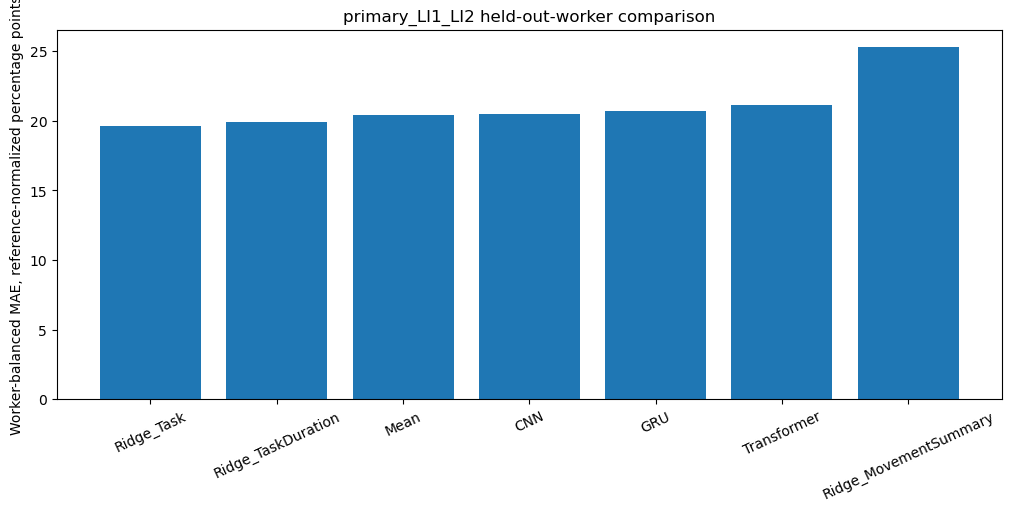

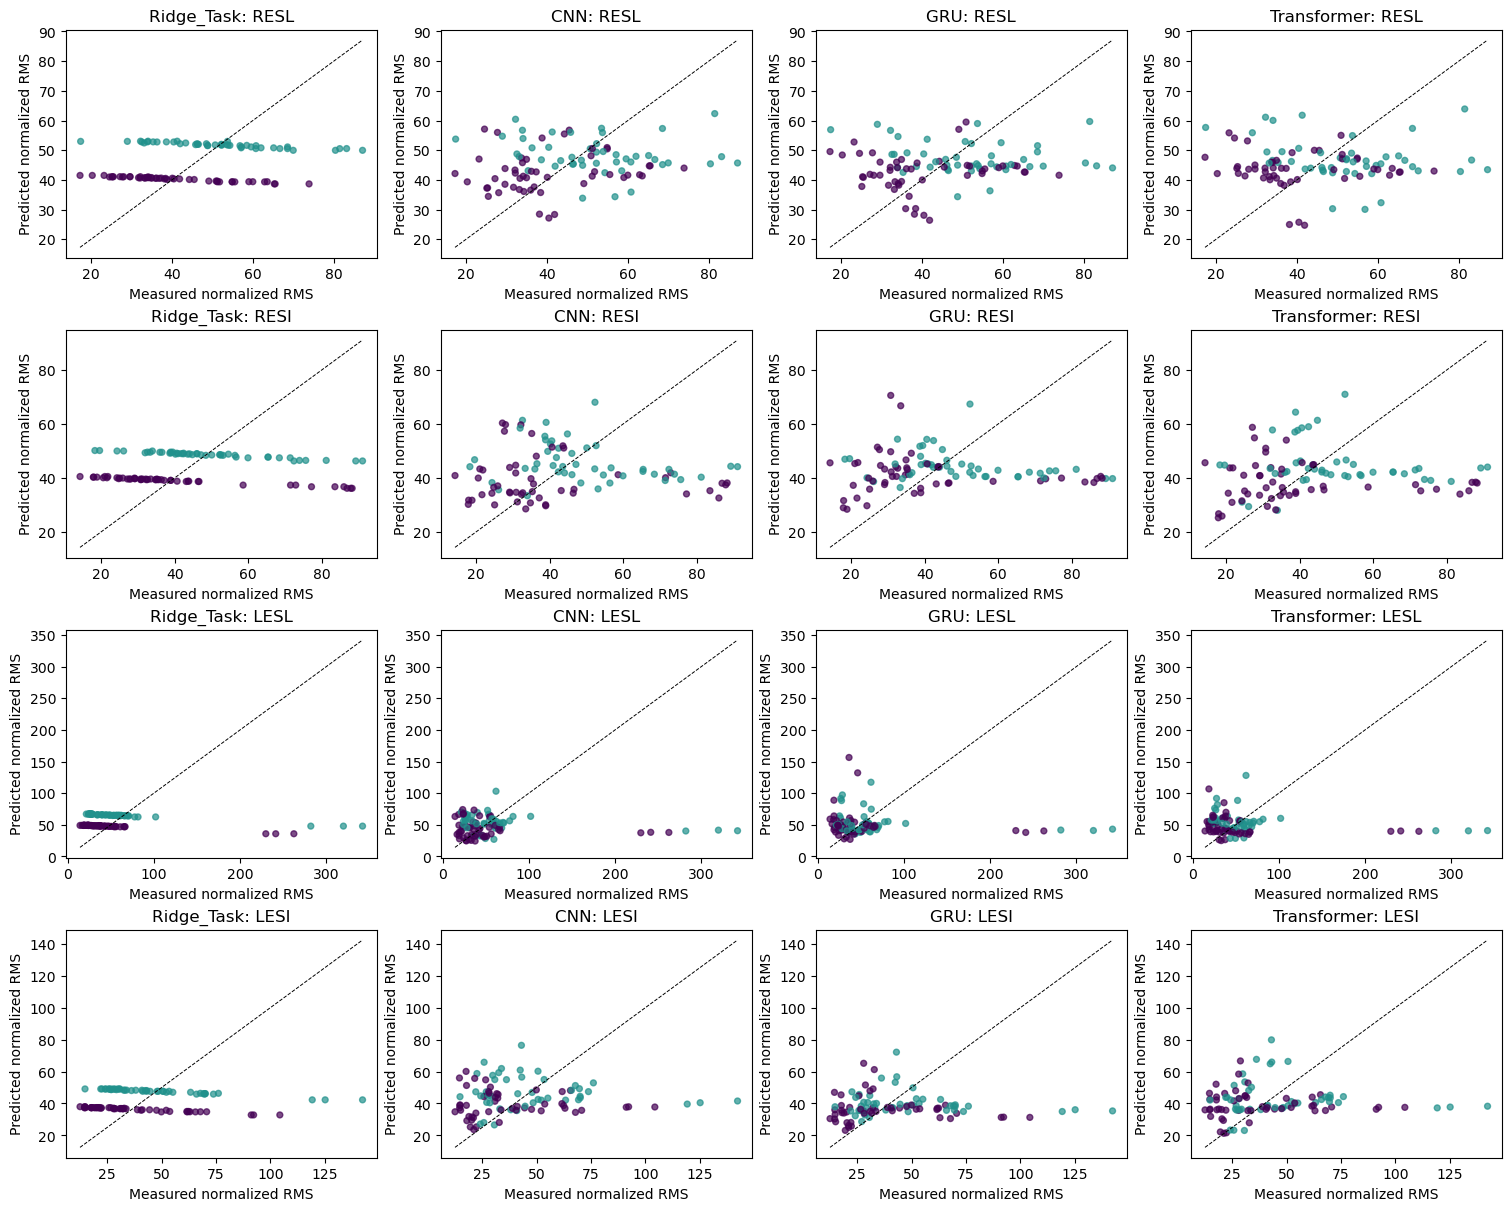

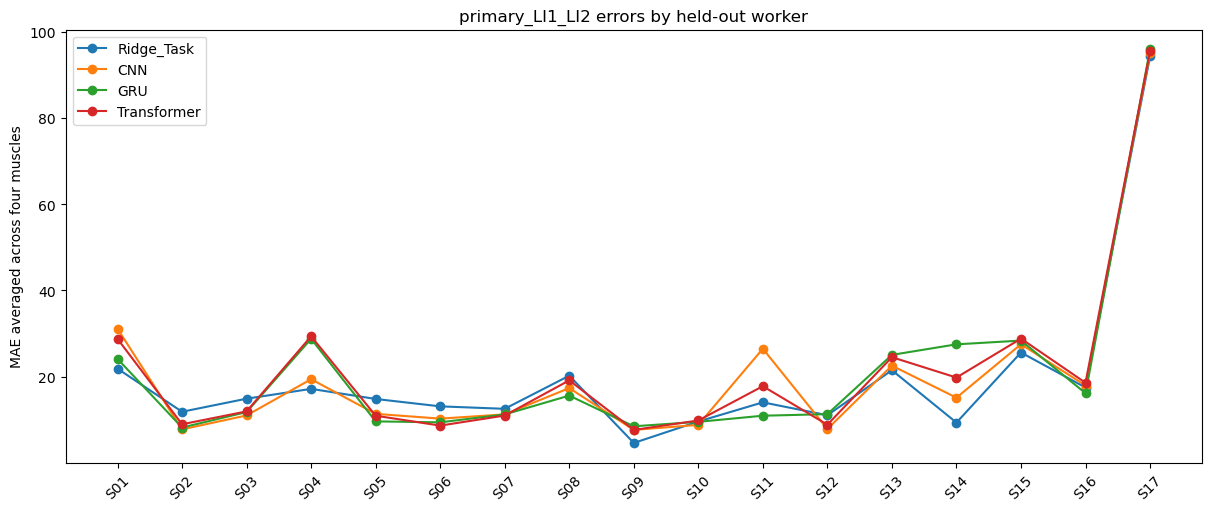

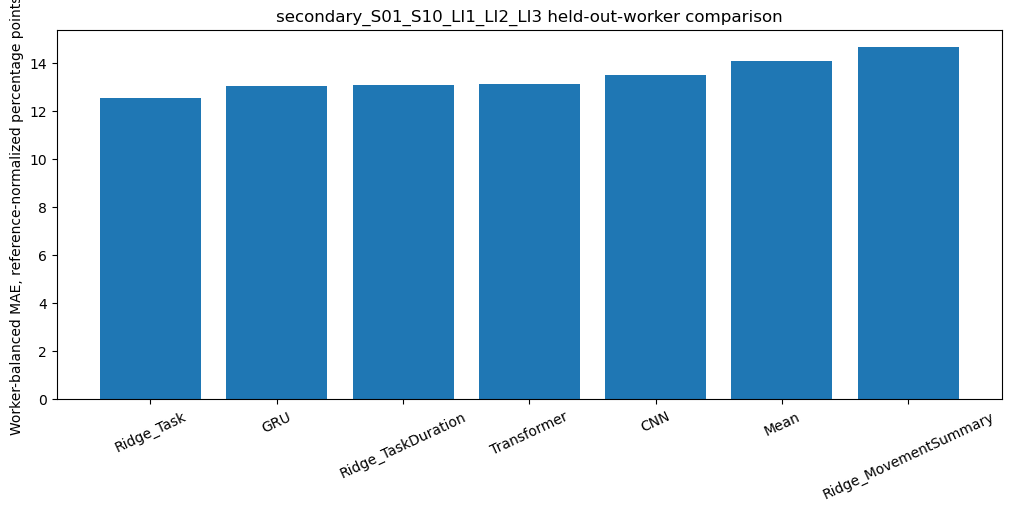

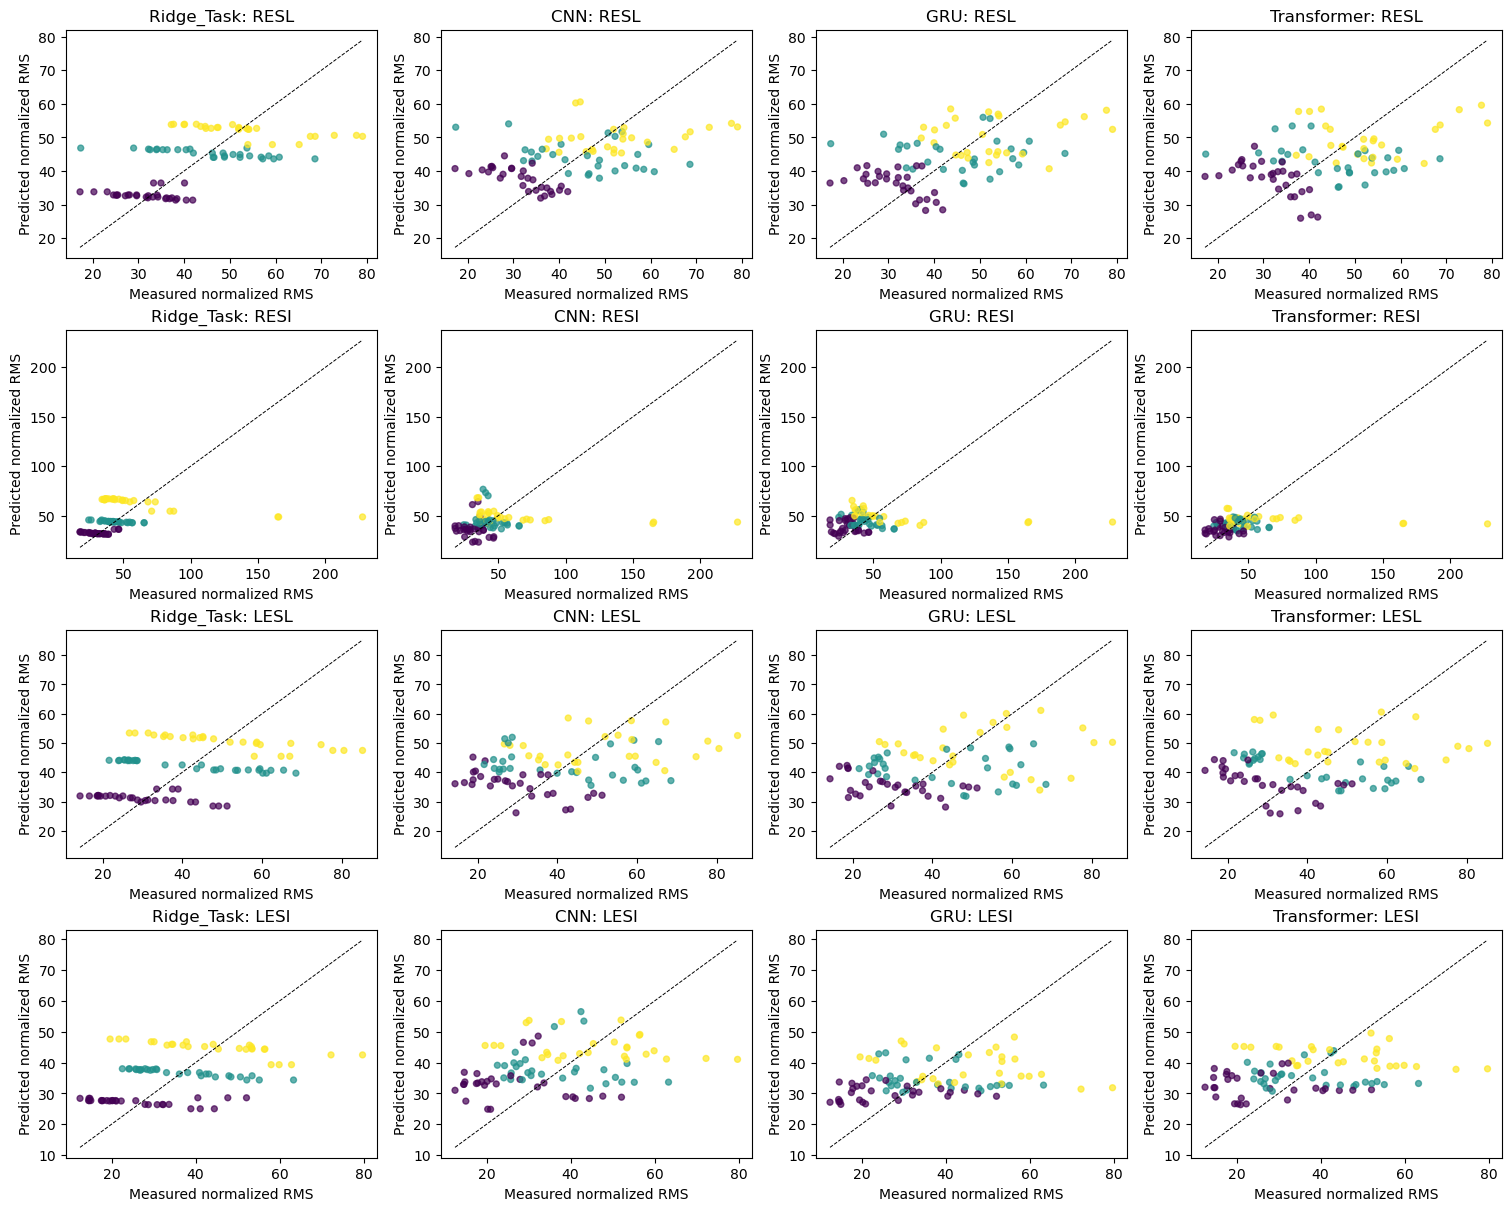

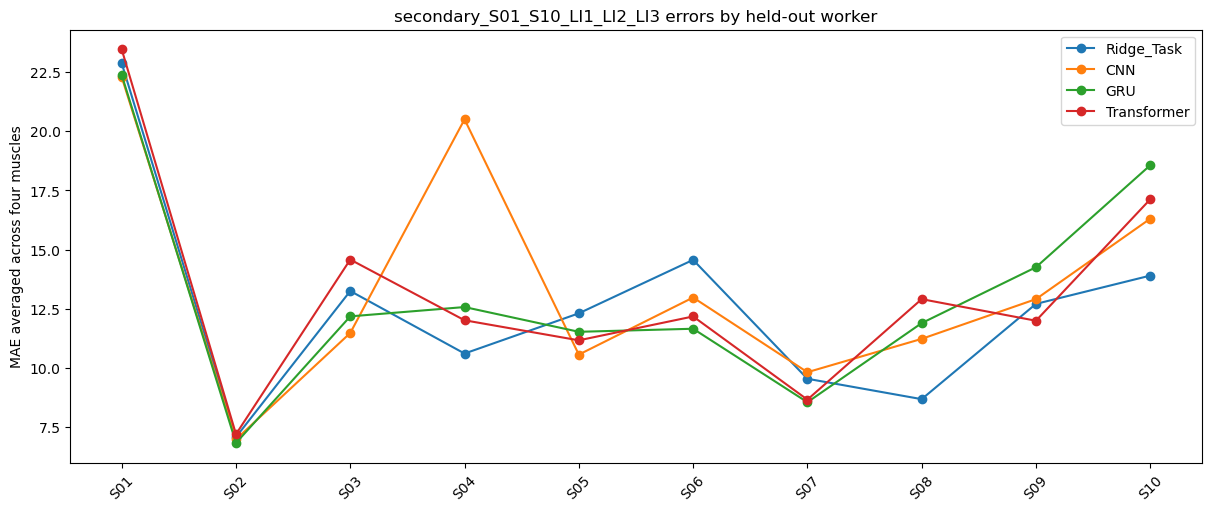

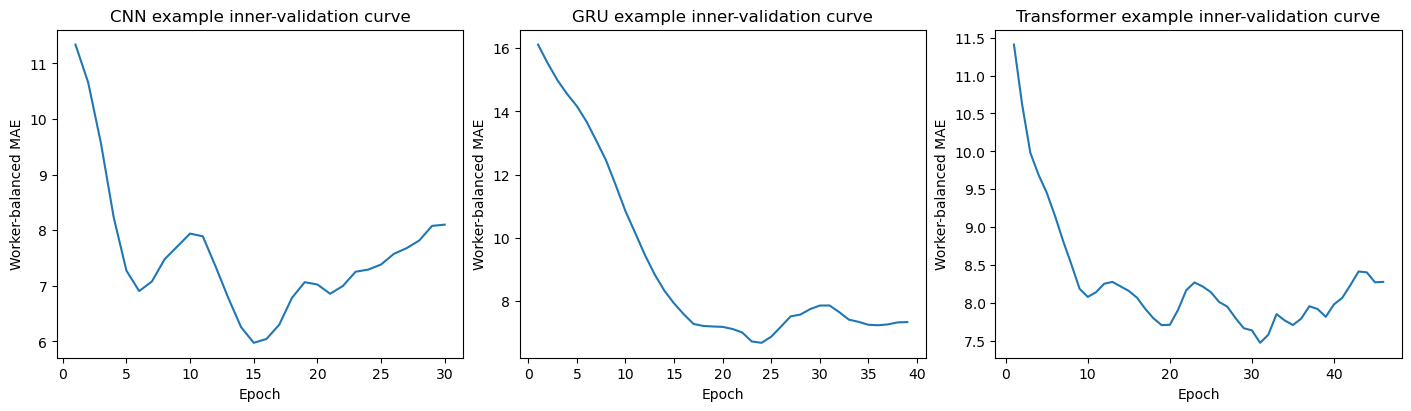

V4 FINISHED
Complete comparison: True
Results: /home/rafsan/Documents/GitHub/IPEXBIO/Project_A/results/INAIL1_EndToEnd_V4/run_20261113T105528_260101Z
UPLOAD THIS ZIP: /home/rafsan/Documents/GitHub/IPEXBIO/Project_A/archives/ProjectA_INAIL1_V4_run_20261113T105528_260101Z.zip
Also save and upload the executed notebook.


In [9]:
figure_paths=[]
for cohort,frame in common_predictions.groupby('cohort'):
    scores=macro[macro.cohort.eq(cohort)].sort_values('worker_balanced_MAE')
    if len(scores):
        fig,ax=plt.subplots(figsize=(10,5),constrained_layout=True)
        ax.bar(scores.model,scores.worker_balanced_MAE)
        ax.tick_params(axis='x',rotation=25)
        ax.set(title=cohort+' held-out-worker comparison',ylabel='Worker-balanced MAE, reference-normalized percentage points')
        p=RUN_DIR/'figures'/f'{cohort}_MAE.png';fig.savefig(p,dpi=150);plt.show();plt.close(fig);figure_paths.append(str(p.relative_to(RUN_DIR)))
    fig,axes=plt.subplots(len(TARGET_CHANNELS),4,figsize=(15,12),constrained_layout=True)
    for col,model in enumerate(['Ridge_Task','CNN','GRU','Transformer']):
        for row,ch in enumerate(TARGET_CHANNELS):
            part=frame[frame.model.eq(model)&frame.channel.eq(ch)]
            ax=axes[row,col]
            ax.scatter(part.y_true,part.y_pred,c=part.LI,cmap='viridis',s=18,alpha=.7,vmin=1,vmax=3)
            if len(part):
                lo=min(part.y_true.min(),part.y_pred.min());hi=max(part.y_true.max(),part.y_pred.max())
                ax.plot([lo,hi],[lo,hi],'k--',linewidth=.7)
            ax.set(title=f'{model}: {ch}',xlabel='Measured normalized RMS',ylabel='Predicted normalized RMS')
    p=RUN_DIR/'figures'/f'{cohort}_predicted_measured.png';fig.savefig(p,dpi=150);plt.show();plt.close(fig);figure_paths.append(str(p.relative_to(RUN_DIR)))
    if not worker_metrics.empty:
        wm=worker_metrics[worker_metrics.cohort.eq(cohort)].groupby(['subject','model']).MAE.mean().unstack()
        fig,ax=plt.subplots(figsize=(12,5),constrained_layout=True)
        for model in ['Ridge_Task','CNN','GRU','Transformer']:
            if model in wm:
                ax.plot(wm.index,wm[model],marker='o',label=model)
        ax.legend();ax.tick_params(axis='x',rotation=45)
        ax.set(title=cohort+' errors by held-out worker',ylabel='MAE averaged across four muscles')
        p=RUN_DIR/'figures'/f'{cohort}_worker_errors.png';fig.savefig(p,dpi=150);plt.show();plt.close(fig);figure_paths.append(str(p.relative_to(RUN_DIR)))
history_paths=sorted((RUN_DIR/'jobs').glob('*_history.csv'))
if history_paths:
    fig,axes=plt.subplots(1,3,figsize=(14,4),constrained_layout=True)
    for ax,kind in zip(axes,['CNN','GRU','Transformer']):
        chosen=next((p for p in history_paths if f'_{kind}_seed' in p.name),None)
        if chosen is not None:
            frame=pd.read_csv(chosen)
            part=frame[frame.stage.eq('epoch_selection')]
            ax.plot(part.epoch,part.validation_worker_MAE)
            ax.set(title=kind+' example inner-validation curve',xlabel='Epoch',ylabel='Worker-balanced MAE')
    p=RUN_DIR/'figures'/'example_validation_curves.png';fig.savefig(p,dpi=150);plt.show();plt.close(fig);figure_paths.append(str(p.relative_to(RUN_DIR)))
completed={r['job_id'] for r in job_rows}
expected=set(expected_jobs)
summary={'version':'4.0','execution':hardware['execution'],'smoke_test':SMOKE_TEST,'run_dir':str(RUN_DIR),'raw_participant_files':len(mat_paths),'prepared_workers':int(meta.subject.nunique()),'prepared_trials':len(meta),'cohorts':cohort_status,'jobs_expected':len(expected),'jobs_completed':len(completed & expected),'jobs_missing':sorted(expected-completed),'job_errors':len(job_errors),'preparation_errors':len(preparation_errors),'comparison_complete':bool(not SMOKE_TEST and expected and expected.issubset(completed) and not job_errors and all(r['status']!='skipped_insufficient_workers' for r in cohort_status)),'comparison_common_channel_rows':len(common_predictions),'performance':macro.to_dict('records'),'paired_comparisons':paired.to_dict('records'),'negative_prediction_rows':int((main_predictions.y_pred<0).sum()),'scientific_status':'exploratory architecture and feasibility pilot; no injury, clinical, causal or publication guarantee','alignment':'TDF nominal clocks with source correspondence; hardware latency not independently certified','normalization':'operational filtered MVC-reference normalization; test-worker MVC used only for outcome reference','feedback_questions':['How many workers and conditions remain after the fixed rules?','Does movement improve on task and task-plus-duration references?','Does improvement persist within conditions and across workers?','Are architecture differences stable across seeds?','Are residuals dominated by a few workers, MVC values or exclusion patterns?','What single methodological change is justified by the observed evidence?']}
save_json(RUN_DIR/'feedback_summary.json',summary)
pd.DataFrame(job_rows).to_csv(RUN_DIR/'job_summary.csv',index=False)
save_json(RUN_DIR/'job_errors.json',job_errors)
save_json(RUN_DIR/'cohort_status.json',cohort_status)
save_json(RUN_DIR/'expected_jobs.json',sorted(expected))
readme=['Project A INAIL 1 V4 feedback package',json.dumps(clean(summary),indent=2),'Read main_performance.csv, paired_worker_comparisons.csv, channel_metrics.csv, prediction_coverage.csv, included_trials.csv and trial_ledger.csv together. Predictions and histories are in jobs/. Reported metrics use the common prediction intersection across all required models. Missing jobs can reduce that intersection; check comparison_complete and job_errors.','Do not treat channel rows, random seeds or interpolated time points as independent workers. Architecture ranking is exploratory. Negative predictions are retained. Task-only Ridge and task-plus-duration Ridge distinguish task identity and duration from additional movement information.','Fixed preparation: movement-only onset reconstruction, source correspondence for the four target channels, phase-local crate support, operational MVC normalization, complete four-channel targets, known duplicate quarantine. Full raw arrays and checkpoints remain local and are excluded from this compact ZIP.','Checkpoints contain numpy scaler metadata and should only be loaded from a trusted run. Use torch.load(..., map_location="cpu", weights_only=False) only for trusted local checkpoints with PyTorch versions that default to weights_only=True.','Upload this ZIP and the saved executed notebook. If a cell fails, include its traceback and the partial ZIP. Do not tune against outer test results and call them untouched confirmation.']
(RUN_DIR/'READ_ME_FIRST.txt').write_text('\n\n'.join(readme),encoding='utf-8')
zip_path=feedback_zip()
print('V4 FINISHED')
print('Complete comparison:',summary['comparison_complete'])
print('Results:',RUN_DIR)
print('UPLOAD THIS ZIP:',zip_path)
print('Also save and upload the executed notebook.')